# Thin-Film Lithium Niobate (TFLN) Electro-Optic Mach-Zehnder Modulator -- Pockels Effect, $V_\pi L$, and Traveling-Wave Bandwidth

`08_mzm.ipynb` built a Mach-Zehnder modulator whose index change $\Delta n$ was
*given* -- a stand-in for "whatever a drive voltage would produce." This
notebook closes that gap for the material the high-speed transceiver industry
is now converging on, **x-cut thin-film lithium niobate (TFLN)**, and follows
the complete chain from volts to modulated light:

1. **Pockels effect** -- how an electric field changes LN's refractive index (section 1).
2. **Optical mode** of the real rib cross-section, with LN's anisotropy, solved with MPB (sections 2-4).
3. **Electrode field** of a ground-signal-ground line, solved electrostatically (section 5).
4. **Overlap** of the two -> $\partial n_\mathrm{eff}/\partial V$ -> the modulator's figure of merit $V_\pi L$ (section 6).
5. A **2D FDTD** check of the full interferometer (splitter, arms, combiner) in TFLN effective indices (sections 7-8).
6. **Traveling-wave RF analysis**: why a ~1 cm electrode is a transmission line, and what limits the electro-optic bandwidth (section 9).

**This notebook deviates from the toolkit's shared modeling convention**
(2D effective index `core_index=2.7`, isotropic): an electro-optic modulator's
figure of merit only exists in the real cross-section, so it uses **real bulk
indices** for LN and silica, LN's **uniaxial anisotropy**, and an **MPB
cross-section solve**, reducing to 2D effective indices only for the FDTD
interferometer check. Materials stay **non-dispersive** across the band
(Sellmeier evaluated once at $\lambda_0=1.35\ \mu$m), like every other
component -- with one labeled exception, the group index used for RF velocity
matching (section 9), where omitting LN's material dispersion would change the
conclusion. See `README.md` "Modeling assumptions".

The electro-optic and RF sections are written as a self-contained primer: no
prior background in electro-optics or microwave engineering is assumed. Each
one goes physical picture -> equations -> typical numbers -> what this notebook
checks.

Work through it step by step and stop at the marked checkpoints. **Do not use
"Run All."** The cross-section and RF sections run in minutes; the FDTD
sections (7-8) take hours on a single core.

## 1. Physical objective

### 1.1 Why thin-film lithium niobate

A transceiver's modulator must turn a ~100 GBd electrical signal into light with
a small drive voltage, low optical loss and a flat frequency response. The
candidate materials, as of 2026:

| Platform | How it modulates | Strength | Limitation |
|---|---|---|---|
| Silicon (carrier depletion) | free-carrier plasma dispersion in a PN junction | CMOS foundries, mature | absorption tied to modulation, RC/carrier-limited bandwidth, nonlinear |
| **TFLN** | Pockels effect, $r_{33}\approx 27$-$31$ pm/V | >100 GHz bandwidth, $V_\pi L\approx 2$ V$\cdot$cm, low loss, linear | lithium contamination in CMOS fabs, DC bias drift |
| Thin-film LiTaO$_3$ | Pockels effect, similar to LN | weaker photorefraction, much lower DC drift | newer, fewer foundries |
| BaTiO$_3$ (BTO) | Pockels, $r_{42}$ up to hundreds of pm/V | grows on silicon | strong dispersion of $r$ and $\varepsilon$ with frequency |
| EO polymers / plasmonics | very large $r$ | compact, very fast | loss, thermal stability |

Integrated TFLN modulators have reached $V_\pi L\approx 1.8$-$2.2$ V$\cdot$cm with
electro-optic bandwidths up to 100 GHz, which makes TFLN a leading candidate for
200 G/lane-class transmitters. Sources (peer-reviewed unless marked):
[Wang et al., *Nature* **562**, 101 (2018)](https://doi.org/10.1038/s41586-018-0551-y),
[Wang et al., *Opt. Express* **26**, 1547 (2018)](https://doi.org/10.1364/OE.26.001547),
[LN/BTO Pockels coefficients from MHz to 330 GHz (*Nature Materials*, 2025)](https://pmc.ncbi.nlm.nih.gov/articles/PMC12133585/),
and, as a concept-level overview only, a
[TFLN/LiTaO$_3$ modulator survey (arXiv 2503.10557, preprint)](https://arxiv.org/html/2503.10557v1).

### 1.2 The Pockels effect from scratch

**Physical picture.** In a crystal without inversion symmetry, an applied
electric field slightly distorts the electron clouds in a direction-dependent
way, so the refractive index changes *in proportion to the field* (linear
electro-optic effect). It is an electronic/ionic response, so it follows the
field essentially instantaneously (THz and beyond) -- unlike silicon
modulators, which must move charge carriers in and out of a junction.

**Index ellipsoid.** An anisotropic crystal's optics is summarized by the
"impermeability" tensor $\eta_{ij} = (\varepsilon^{-1})_{ij}$. In the crystal's
principal axes,

$$\frac{x^2}{n_x^2} + \frac{y^2}{n_y^2} + \frac{z^2}{n_z^2} = 1 ,$$

and a field $\mathbf{E}$ perturbs each coefficient linearly:

$$\Delta\!\left(\frac{1}{n^2}\right)_{i} = \sum_k r_{ik}\, E_k \qquad (i = 1\ldots6 \text{ in contracted notation}).$$

$r_{ik}$ (units m/V, typically quoted in pm/V) is the **electro-optic tensor**.
LN belongs to point group $3m$; its nonzero components are
$r_{13}=r_{23}$, $r_{33}$, $r_{22}=-r_{12}=-r_{61}$, $r_{42}=r_{51}$. The largest
by far is $r_{33}\approx 31$ pm/V, which couples a field along the optic
(crystal $Z$) axis to light polarized along that same axis.

**From $\Delta(1/n^2)$ to $\Delta n$.** For light polarized along $Z$ and a
field $E_Z$ along $Z$:

$$\Delta\!\left(\frac{1}{n_e^2}\right) = r_{33} E_Z
\;\;\Longrightarrow\;\; -\frac{2}{n_e^3}\,\Delta n_e = r_{33}E_Z
\;\;\Longrightarrow\;\; \boxed{\Delta n_e = -\tfrac{1}{2}\, n_e^3\, r_{33}\, E_Z}$$

(differentiate $1/n^2$: $d(1/n^2) = -2\,dn/n^3$). The equivalent statement for
the permittivity, used by the solvers below, is
$\Delta\varepsilon_{ZZ} = -n_e^4\, r_{33}\, E_Z$.

**Typical size.** $n_e\approx2.14$, $r_{33}=30.9$ pm/V and a field of
1 V across a 5 $\mu$m gap ($2\times10^5$ V/m) give
$|\Delta n_e| \approx \tfrac12 (2.14)^3 (30.9\times10^{-12})(2\times10^5)\approx 3\times10^{-5}$.
Tiny -- which is why the phase is accumulated over a ~cm-long arm, and why
the figure of merit is the voltage-length product $V_\pi L$.

**Figure of merit $n^3 r$.** Because $\Delta n\propto n^3 r$, materials are
compared by $n^3r$: LN gives $\approx 2.14^3\times 31\approx 300$ pm/V.

### 1.3 Geometry: x-cut, TE light, lateral electrodes

In **x-cut** LN the wafer surface is normal to crystal $X$, so the optic axis
$Z$ lies **in the chip plane**. Propagating along crystal $Y$:

| Lab axis (this notebook) | Crystal axis | Optical index | Role |
|---|---|---|---|
| $x$ -- lateral, in-plane, across the rib | $Z$ (optic axis) | $n_e$ | TE light's E-field and the electrode field both point here -> $r_{33}$ |
| $y$ -- vertical | $X$ | $n_o$ | |
| $z$ -- propagation | $Y$ | $n_o$ | |

So a **TE** mode (E mostly lateral) and **coplanar electrodes on either side of
the rib** (field mostly lateral) both line up with the optic axis, and the
device uses the largest coefficient, $r_{33}$. The same TE/TM choice also
matters numerically: in x-cut TFLN the fundamental TE and TM modes are nearly
degenerate (section 3), so the solver must be told which one is wanted.

**Key points.** (i) Pockels: $\Delta n_e=-\tfrac12 n_e^3 r_{33} E$ -- linear in
field and essentially instantaneous. (ii) x-cut + TE + lateral electrodes is
the geometry that uses $r_{33}$. (iii) $|\Delta n|\sim10^{-5}$ per volt, hence
cm-long arms.

In [1]:
import json
import time

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

import meep as mp
from pic_toolkit.meep_sim import tfln_waveguide as tw, tfln_electrostatics as es, tfln_mzm as tm
from pic_toolkit.meep_sim import coupler, mzm
from pic_toolkit import viz, design_points, style

style.apply_style()  # shared color palette + plot style for every notebook in this toolkit
%matplotlib inline

# ============================================================
# USER PARAMETERS -- one shared layer stack for the optical (MPB) and
# electrical (electrostatic) solvers; tm.combined_params copies the film /
# etch / rib width from the optical dict into the electrical one so they can
# never disagree.
# ============================================================
optical, electrical = tm.combined_params(
    optical=dict(),      # tfln_waveguide.DEFAULT_PARAMS: 600 nm film, 300 nm etch, 1.0 um rib
    electrical=dict(),   # tfln_electrostatics.DEFAULT_PARAMS: GSG, 5 um gaps, 20 um signal, 1 um Au, 2 um BOX
)
WL0 = optical["wl0_um"]
R33 = tm.R33_CLASSIC_M_PER_V          # 30.9 pm/V; the 26.9 pm/V broadband value is reported alongside
mat = tw.materials(optical)

# Constant (wl0-evaluated) material indices -- the toolkit's non-dispersive convention.
print(f"wl0 = {WL0} um")
print(f"LN  n_o = {mat['n_o']:.4f}   n_e = {mat['n_e']:.4f}   (Zelmon 1997, congruent LN)")
print(f"SiO2 n  = {mat['n_sio2']:.4f}              (Malitson 1965)")
print(f"LN figure of merit n_e^3 r33 = {mat['n_e']**3 * R33 * 1e12:.0f} pm/V")

wl0 = 1.35 um
LN  n_o = 2.2184   n_e = 2.1437   (Zelmon 1997, congruent LN)
SiO2 n  = 1.4464              (Malitson 1965)
LN figure of merit n_e^3 r33 = 304 pm/V


## 2. Cross-section geometry

The device cross-section, left to right: ground electrode | gap with rib
waveguide (arm 1) | signal electrode | gap with rib waveguide (arm 2) | ground
electrode. Below the LN film are the buried oxide and the silicon handle; above
is air.

**Partial etch, not under-etch.** The 600 nm LN film is etched only 300 nm
deep, so each waveguide is a 600 nm-tall, 1.0 $\mu$m-wide **rib** standing on a
300 nm LN **slab** that continues sideways under the electrodes. This is a
deliberate *partial* (shallow) etch, and it is exactly the structure every
solver in this notebook uses. It is **not** an "under-etch" in the sense of a
fabrication defect (an etch that failed to reach its target depth), and **not**
an undercut (material removed underneath the rib). Why a partial etch:

- **Optics.** The rib's extra 300 nm of LN raises the local effective index
  ($n_\mathrm{core}\approx1.99$ vs $n_\mathrm{slab}\approx1.79$ in section 4)
  enough to guide the TE mode laterally, while the low index contrast keeps the
  mode from crowding the etched sidewalls, where roughness scatters light.
- **Electro-optics.** The electrodes sit on the slab, so their field enters the
  LN directly and runs laterally through the slab and the rib -- the field
  inside the waveguide is what produces the index change (sections 5-6). A full
  etch would put a low-permittivity air/oxide gap between electrode and rib.
- **Single-mode width.** With the slab present, a 1.0 $\mu$m rib stays
  single-mode in TE (section 3.4).

Sidewalls are modeled as vertical; real TFLN ribs are typically sloped, which is
listed among the unmodeled effects in section 12.

In the permittivity maps below, the rib and the slab have the same colour
because they are the same material. The rib is the 1 $\mu$m-wide bump on top of
the slab. The two panels differ because LN is anisotropic: the lateral
component $\varepsilon_{xx}=n_e^2$ is smaller than the vertical
$\varepsilon_{yy}=n_o^2$.

The optical solver only needs a window around ONE rib (the mode decays within
~1-2 $\mu$m), while the electrostatic solver needs the whole electrode structure
and a far boundary hundreds of microns away. Both share the same layer stack.

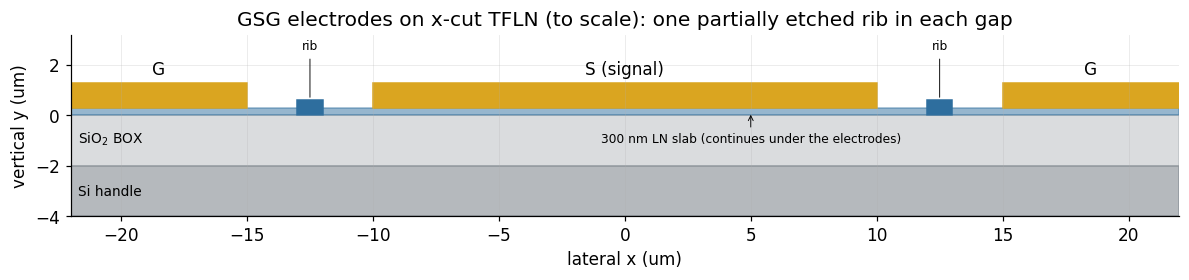

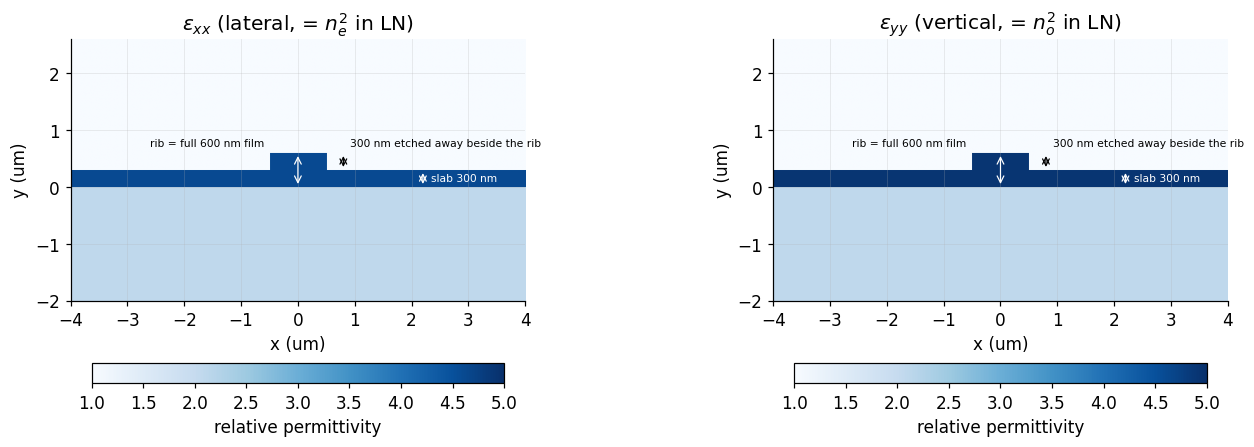

In [2]:
# Full-device cross-section (equal aspect, electrode region only) and the optical
# solver's permittivity map around one rib -- both components of the anisotropic
# LN tensor are shown, since the TE mode sees eps_x = n_e^2 while eps_y = n_o^2.
lay = es.electrode_layout(electrical)
slab_t = optical["film_um"] - optical["etch_um"]
XL = 22.0                          # lateral window: both gaps and the inner ground edges
fig, ax = plt.subplots(figsize=(13, 3.0))
ax.add_patch(Rectangle((-XL, -electrical["box_um"]), 2 * XL, electrical["box_um"], color=style.COLOR_REFERENCE, alpha=0.25))
ax.add_patch(Rectangle((-XL, -4), 2 * XL, 4 - electrical["box_um"], color=style.COLOR_REFERENCE, alpha=0.5))
ax.add_patch(Rectangle((-XL, 0), 2 * XL, slab_t, color=style.COLOR_STEEL, alpha=0.5))
for c in lay["wg_centers"]:
    ax.add_patch(Rectangle((c - optical["rib_width_um"] / 2, 0), optical["rib_width_um"], optical["film_um"],
                           color=style.COLOR_STEEL))
for name in ("ground_left", "signal", "ground_right"):
    a, b = lay[name]
    a, b = max(a, -XL), min(b, XL)
    ax.add_patch(Rectangle((a, slab_t), b - a, electrical["metal_um"], color="goldenrod"))
top = slab_t + electrical["metal_um"]
ax.text(0, top + 0.3, "S (signal)", ha="center")
ax.text((-XL + lay["ground_left"][1]) / 2, top + 0.3, "G", ha="center")
ax.text((XL + lay["ground_right"][0]) / 2, top + 0.3, "G", ha="center")
for c in lay["wg_centers"]:
    ax.annotate("rib", (c, optical["film_um"]), xytext=(c, 2.6), ha="center", fontsize=8,
                arrowprops=dict(arrowstyle="-", lw=0.6, color="k"))
ax.text(-XL + 0.3, -1.1, "SiO$_2$ BOX", fontsize=9)
ax.text(-XL + 0.3, -3.2, "Si handle", fontsize=9)
ax.annotate("300 nm LN slab (continues under the electrodes)", (5.0, slab_t / 2), xytext=(5.0, -1.1), fontsize=8,
            ha="center", arrowprops=dict(arrowstyle="->", lw=0.6, color="k"))
ax.set_xlim(-XL, XL); ax.set_ylim(-4, 3.2); ax.set_aspect("equal")
ax.set_xlabel("lateral x (um)"); ax.set_ylabel("vertical y (um)")
ax.set_title("GSG electrodes on x-cut TFLN (to scale): one partially etched rib in each gap")
plt.show()

x_opt, y_opt = np.linspace(-4, 4, 400), np.linspace(-2, 2.6, 230)
maps = tw.eps_diag_maps(optical, x_opt, y_opt)
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
for a, key, lab in ((axs[0], "eps_x", r"$\varepsilon_{xx}$ (lateral, = $n_e^2$ in LN)"),
                    (axs[1], "eps_y", r"$\varepsilon_{yy}$ (vertical, = $n_o^2$ in LN)")):
    im = a.imshow(maps[key], origin="lower", extent=(x_opt[0], x_opt[-1], y_opt[0], y_opt[-1]),
                  cmap=style.CMAP_PERMITTIVITY_BASELINE, vmin=1, vmax=5, aspect="equal")
    a.set_title(lab); a.set_xlabel("x (um)"); a.set_ylabel("y (um)")
    # dimension marks: 600 nm film = 300 nm slab + 300 nm etched rib
    a.annotate("", (2.2, 0), (2.2, slab_t), arrowprops=dict(arrowstyle="<->", color="w", lw=0.8))
    a.text(2.35, slab_t / 2, "slab 300 nm", color="w", fontsize=7, va="center")
    a.annotate("", (0, 0), (0, optical["film_um"]), arrowprops=dict(arrowstyle="<->", color="w", lw=0.8))
    a.text(-0.6, optical["film_um"] + 0.12, "rib = full 600 nm film", color="k", fontsize=7, ha="right")
    a.annotate("", (0.8, slab_t), (0.8, optical["film_um"]), arrowprops=dict(arrowstyle="<->", color="k", lw=0.8))
    a.text(0.92, optical["film_um"] + 0.12, "300 nm etched away beside the rib", color="k", fontsize=7)
    plt.colorbar(im, ax=a, orientation="horizontal", fraction=0.06, pad=0.18, label="relative permittivity")
plt.tight_layout(); plt.show()

## 3. Optical mode (MPB)

**What is solved.** For a waveguide uniform along $z$, guided light has the
form $\mathbf{E}(x,y)\,e^{i(\beta z-\omega t)}$. MPB solves Maxwell's equations
on the 2D cross-section as an eigenproblem; `find_k` fixes the frequency
$\omega=2\pi c/\lambda_0$ and finds $\beta$, so $n_\mathrm{eff}=\beta/k_0$.
It also returns the group velocity, giving the **group index**
$n_g = c/v_g = n_\mathrm{eff}-\lambda\, dn_\mathrm{eff}/d\lambda$ -- the speed
at which a modulated signal (an envelope) travels, which section 9 needs.

**TE vs TM is a real hazard here.** MPB separates modes by mirror symmetry.
Because the stack is not up-down symmetric, only the lateral mirror is usable,
and MPB can only exploit a mirror along its own $y$ axis -- so the module
rotates the lattice (MPB $x$ = vertical, MPB $y$ = lateral) and converts back.
The TE mode, whose lateral field is even across the rib, is labeled `ODD_Y`
in that rotated lattice (the mirror also flips the sign of the lateral vector
component). The check below shows why the parity must be explicit: TE and TM
are within ~$10^{-3}$ of each other.

In [3]:
# 3.1 TE, TM and a parity-free solve on the same cross-section.
for label, parity in (("TE  (ODD_Y)", tw.TE_PARITY), ("TM  (EVEN_Y)", tw.TM_PARITY), ("NO_PARITY", mp.NO_PARITY)):
    m = tw.solve_mode(optical, parity=parity)
    print(f"{label:14s} n_eff = {m.n_eff:.5f}   TE fraction (|Ex|^2 share) = {m.te_fraction:.3f}")

TE  (ODD_Y)    n_eff = 1.92632   TE fraction (|Ex|^2 share) = 0.947


TM  (EVEN_Y)   n_eff = 1.92472   TE fraction (|Ex|^2 share) = 0.012


NO_PARITY      n_eff = 1.92472   TE fraction (|Ex|^2 share) = 0.012


The TE and TM indices differ only in the third decimal place, and the
parity-free solve picks whichever its root search converges to. Every solve
below therefore passes the TE parity explicitly and prints the TE fraction.

**Axis sanity check.** If the anisotropy is wired correctly, the TE mode feels
$\varepsilon_{xx}$. Swapping $n_e\leftrightarrow n_o$ on the lateral axis must
then raise $n_\mathrm{eff}$ (since $n_o>n_e$), and by roughly the
confinement-weighted index difference.

In [4]:
# 3.2 Swap n_e <-> n_o on the lateral axis: TE n_eff must move up by a large fraction of n_o - n_e.
m_ok = tw.solve_mode(optical)
m_sw = tw.solve_mode(optical, swap_axes=True)
print(f"n_eff with lateral = n_e : {m_ok.n_eff:.5f}")
print(f"n_eff with lateral = n_o : {m_sw.n_eff:.5f}   (n_o - n_e = {mat['n_o'] - mat['n_e']:.4f})")
assert m_sw.n_eff - m_ok.n_eff > 0.5 * (mat["n_o"] - mat["n_e"]), "TE mode is not seeing the lateral (n_e) permittivity"

n_eff with lateral = n_e : 1.92632
n_eff with lateral = n_o : 1.99808   (n_o - n_e = 0.0746)


res  16: n_eff = 1.92534   n_g = 2.2498   (0.1 s)


res  24: n_eff = 1.92590   n_g = 2.2501   (0.3 s)


res  32: n_eff = 1.92632   n_g = 2.2506   (0.8 s)


res  48: n_eff = 1.92684   n_g = 2.2513   (1.7 s)


res  64: n_eff = 1.92692   n_g = 2.2514   (3.4 s)


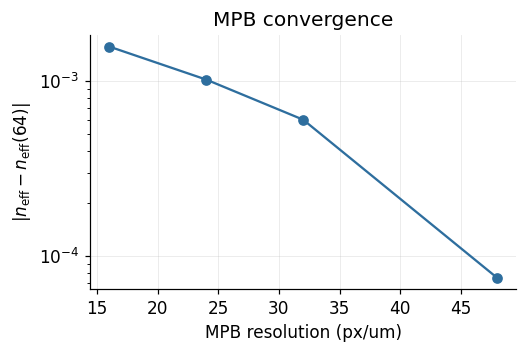

In [5]:
# 3.3 Resolution convergence of n_eff (and n_g). The production resolution is
# the coarsest one whose n_eff is within the stated tolerance of the finest run.
RES_LIST = [16, 24, 32, 48, 64]
conv = {}
for r in RES_LIST:
    t0 = time.time()
    m = tw.solve_mode(optical, resolution=r)
    conv[r] = (m.n_eff, m.n_g)
    print(f"res {r:3d}: n_eff = {m.n_eff:.5f}   n_g = {m.n_g:.4f}   ({time.time() - t0:.1f} s)")
ref = conv[RES_LIST[-1]][0]
fig, ax = plt.subplots(figsize=(5, 3))
ax.semilogy(RES_LIST[:-1], [abs(conv[r][0] - ref) for r in RES_LIST[:-1]], "o-", color=style.COLOR_STEEL)
ax.set_xlabel("MPB resolution (px/um)"); ax.set_ylabel(r"$|n_\mathrm{eff}-n_\mathrm{eff}(64)|$")
ax.set_title("MPB convergence"); plt.show()

In [6]:
# Production resolution: n_eff within 1e-3 of the finest run is far below anything
# that matters for V_pi L (it enters only through n_g and the mode shape).
RES_TOL = 1e-3
RES_MPB = optical["resolution"]
print(f"production resolution {RES_MPB}: |dn_eff| vs res 64 = {abs(conv[RES_MPB][0] - ref):.1e} (tolerance {RES_TOL:.0e})")
assert abs(conv[RES_MPB][0] - ref) < RES_TOL

# MPB cell-size check: deeper oxide, taller air, wider window must not move n_eff.
for k, v in (("box_um", 3.0), ("air_um", 3.0), ("cell_lateral_um", 10.0)):
    m = tw.solve_mode({**optical, k: v})
    print(f"{k} -> {v}: n_eff = {m.n_eff:.5f}  (change {m.n_eff - m_ok.n_eff:+.1e})")

production resolution 32: |dn_eff| vs res 64 = 6.0e-04 (tolerance 1e-03)
box_um -> 3.0: n_eff = 1.92662  (change +3.0e-04)


air_um -> 3.0: n_eff = 1.92650  (change +1.8e-04)


cell_lateral_um -> 10.0: n_eff = 1.92625  (change -6.6e-05)


**Single-mode width.** A modulator arm should carry only the fundamental TE
mode; a second TE mode would beat against it and spoil the interference. A mode
is guided only if its $n_\mathrm{eff}$ exceeds the TE index of the etched slab
on either side (otherwise it leaks sideways). Note that the *first-order* TE
mode (lateral field odd across the rib) falls in MPB's other mirror family
(`EVEN_Y`, with TM0), so both families are solved and every guided band is
labeled by its TE fraction.

w = 0.6 um: 1 guided TE mode(s): 1.8643


w = 0.8 um: 1 guided TE mode(s): 1.9012


w = 1.0 um: 1 guided TE mode(s): 1.9263


w = 1.2 um: 2 guided TE mode(s): 1.9430, 1.8162


w = 1.5 um: 2 guided TE mode(s): 1.9588, 1.8605


w = 2.0 um: 3 guided TE mode(s): 1.9727, 1.9100, 1.8174


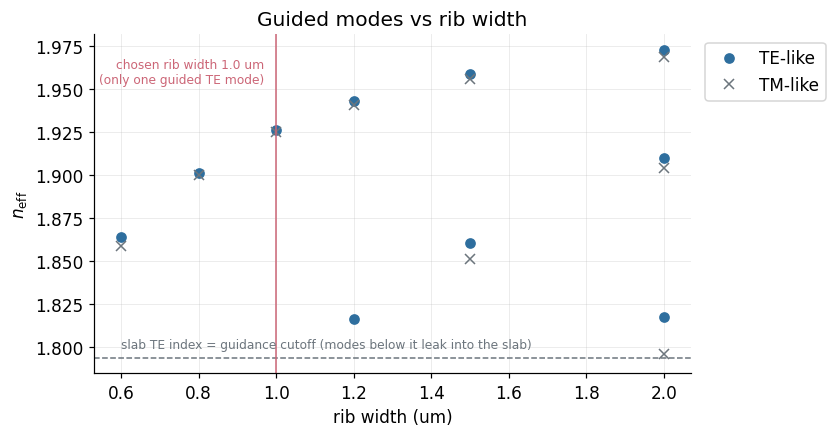

In [7]:
# 3.4 Guided modes vs rib width.
WIDTHS = [0.6, 0.8, 1.0, 1.2, 1.5, 2.0]
n_slab = tw.eim_indices(optical)["clad_index"]
rows = {}
for w in WIDTHS:
    rows[w] = tw.guided_modes({**optical, "rib_width_um": w})
    te = [d for d in rows[w] if d["te_fraction"] > 0.5]
    print(f"w = {w:.1f} um: {len(te)} guided TE mode(s): " + ", ".join(f"{d['n_eff']:.4f}" for d in te))

fig, ax = plt.subplots(figsize=(7, 4))
for w in WIDTHS:
    for d in rows[w]:
        is_te = d["te_fraction"] > 0.5
        ax.plot(w, d["n_eff"], "o" if is_te else "x", color=style.COLOR_STEEL if is_te else style.COLOR_REFERENCE)
ax.axhline(n_slab, color=style.COLOR_REFERENCE, ls="--", lw=1)
ax.text(WIDTHS[0], n_slab + 0.004, "slab TE index = guidance cutoff (modes below it leak into the slab)",
        fontsize=8, color=style.COLOR_REFERENCE, ha="left", va="bottom")
w0 = optical["rib_width_um"]
ax.axvline(w0, color=style.COLOR_ROSE, lw=1)
ax.text(w0 - 0.03, 1.968, f"chosen rib width {w0:.1f} um\n(only one guided TE mode)", color=style.COLOR_ROSE, fontsize=8,
        ha="right", va="top")
ax.plot([], [], "o", color=style.COLOR_STEEL, label="TE-like"); ax.plot([], [], "x", color=style.COLOR_REFERENCE, label="TM-like")
ax.set_xlabel("rib width (um)"); ax.set_ylabel(r"$n_\mathrm{eff}$"); ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0)); ax.set_title("Guided modes vs rib width")
plt.show()
n_te = sum(d["te_fraction"] > 0.5 for d in rows[optical["rib_width_um"]])
assert n_te == 1, "the chosen rib width is not single-mode in TE"

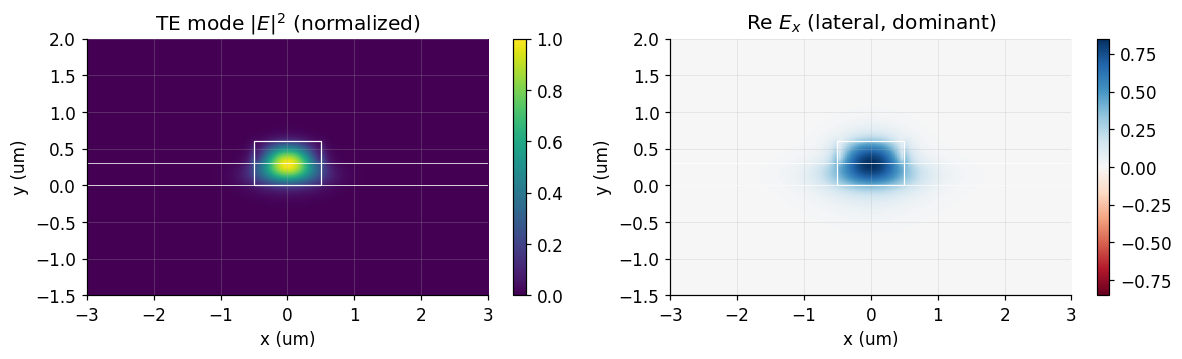

n_eff = 1.9263, TE fraction = 0.947
n_g (indices frozen at wl0, toolkit convention)      = 2.2506
n_g (LN + SiO2 material dispersion included)         = 2.2973  <- used for RF velocity matching


In [8]:
# 3.5 The fundamental TE mode at the chosen width, and its group index.
mode = tw.solve_mode(optical)
ng = tw.group_index_dispersive(optical)
I = np.abs(mode.Ex) ** 2 + np.abs(mode.Ey) ** 2 + np.abs(mode.Ez) ** 2
ext = (mode.x_um[0], mode.x_um[-1], mode.y_um[0], mode.y_um[-1])
fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
im = axs[0].imshow(I / I.max(), origin="lower", extent=ext, cmap=style.CMAP_DENSITY, aspect="auto")
axs[0].set_title(r"TE mode $|E|^2$ (normalized)"); plt.colorbar(im, ax=axs[0])
ex = np.real(mode.Ex * np.exp(-1j * np.angle(mode.Ex[np.unravel_index(np.argmax(np.abs(mode.Ex)), mode.Ex.shape)])))
v = np.abs(ex).max()
im = axs[1].imshow(ex, origin="lower", extent=ext, cmap=style.CMAP_FIELD, vmin=-v, vmax=v, aspect="auto")
axs[1].set_title(r"Re $E_x$ (lateral, dominant)"); plt.colorbar(im, ax=axs[1])
for a in axs:
    a.set_xlim(-3, 3); a.set_ylim(-1.5, 2); a.set_xlabel("x (um)"); a.set_ylabel("y (um)")
    a.add_patch(Rectangle((-optical["rib_width_um"] / 2, 0), optical["rib_width_um"], optical["film_um"], fill=False, ec="w", lw=0.8))
    a.axhline(slab_t, color="w", lw=0.5); a.axhline(0, color="w", lw=0.5)
plt.tight_layout(); plt.show()
print(f"n_eff = {mode.n_eff:.4f}, TE fraction = {mode.te_fraction:.3f}")
print(f"n_g (indices frozen at wl0, toolkit convention)      = {ng['n_g_nondispersive']:.4f}")
print(f"n_g (LN + SiO2 material dispersion included)         = {ng['n_g_dispersive']:.4f}  <- used for RF velocity matching")

## 4. Effective-index reduction for the 2D FDTD

The full interferometer (two couplers + arms, hundreds of microns) is far too
large for 3D FDTD here. The **effective index method (EIM)** collapses the
vertical direction: each lateral region is replaced by the TE index of the
vertical slab it contains --

- rib region: 600 nm LN film on SiO$_2$ under air -> core index $n_\mathrm{core}$,
- etched region: 300 nm LN slab -> cladding index $n_\mathrm{clad}$,

each from the analytic asymmetric-slab TE dispersion relation
$\kappa t = \arctan(\gamma_s/\kappa) + \arctan(\gamma_c/\kappa)$ with
$\kappa=k_0\sqrt{n_e^2-n^2}$, $\gamma_{s,c}=k_0\sqrt{n^2-n_{s,c}^2}$. A 2D top-view
waveguide with these two indices is then what Meep simulates.

EIM is approximate, and least accurate for low-contrast ribs like this one, so
its error is **measured** against the MPB result rather than assumed small.

In [9]:
eim = tw.eim_indices(optical)
wg2d = tm.eim_waveguide_neff(eim["core_index"], eim["clad_index"], optical["rib_width_um"], WL0)
PHASE_FACTOR = tm.phase_response_factor(eim["core_index"], eim["clad_index"], optical["rib_width_um"], WL0)
print(f"EIM core index (600 nm film) = {eim['core_index']:.4f}")
print(f"EIM clad index (300 nm slab) = {eim['clad_index']:.4f}   (contrast {eim['core_index'] - eim['clad_index']:.3f})")
print(f"2D EIM waveguide n_eff = {wg2d['n_eff']:.4f}  vs  MPB cross-section n_eff = {mode.n_eff:.4f}"
      f"  -> EIM error {100 * (wg2d['n_eff'] / mode.n_eff - 1):+.2f} %")
print(f"2D EIM n_g = {wg2d['n_g']:.3f}  vs  MPB n_g = {mode.n_g:.3f} (both non-dispersive)")
print(f"phase-response factor d n_eff / d n_core (2D) = {PHASE_FACTOR:.3f}")

EIM core index (600 nm film) = 1.9945
EIM clad index (300 nm slab) = 1.7940   (contrast 0.201)
2D EIM waveguide n_eff = 1.9384  vs  MPB cross-section n_eff = 1.9263  -> EIM error +0.63 %
2D EIM n_g = 2.013  vs  MPB n_g = 2.251 (both non-dispersive)
phase-response factor d n_eff / d n_core (2D) = 0.898


EIM puts $n_\mathrm{eff}$ within about a percent, but it underestimates the group
index noticeably: freezing the two slab indices at $\lambda_0$ discards the
slab's own waveguide dispersion. That is acceptable for what the 2D FDTD is
used for (the coupler split and the interferometer's phase-to-intensity
transfer at $\lambda_0$), and it is why every group-index-sensitive quantity in
this notebook (section 9) uses the MPB value instead.

The **phase-response factor** $\partial n_\mathrm{eff}/\partial n_\mathrm{core}<1$
replaces `mzm.py`'s empirically carried `phase_factor_prior`: in this
low-contrast guide a sizeable part of the mode sits in the cladding, so
raising only the core index moves $n_\mathrm{eff}$ by less.

## 5. Electrode field (electrostatics)

### 5.1 Why an electrostatic solve is enough

At 100 GHz the RF wavelength in this structure is about $c/(f\,n_\mathrm{RF})\approx1.4$ mm,
while the cross-section features are microns. Over such a small cross-section
the field has, at every instant, the shape of the static field for the
instantaneous voltage -- the **quasi-static** (quasi-TEM) approximation. The
time dependence is handled separately by transmission-line theory (section 9).

### 5.2 The equation

With no free charge in the dielectrics, $\nabla\cdot\mathbf{D}=0$ and
$\mathbf{E}=-\nabla\phi$. LN is anisotropic at RF too, so
$\mathbf{D}=\varepsilon_0\,\mathrm{diag}(\varepsilon_x,\varepsilon_y)\,\mathbf{E}$
and

$$\frac{\partial}{\partial x}\!\left(\varepsilon_x\frac{\partial\phi}{\partial x}\right)+\frac{\partial}{\partial y}\!\left(\varepsilon_y\frac{\partial\phi}{\partial y}\right)=0 ,$$

with $\phi=V$ on the signal electrode, $\phi=0$ on the grounds and on a far
boundary. The solver (`tfln_electrostatics.solve_field`) discretizes this with
finite volumes on a non-uniform grid (25 nm cells near the gaps, growing to
50 $\mu$m cells 1.5 mm away), with every interface on a grid line so the
large permittivity jumps are handled exactly.

### 5.3 The physics to look for

- **The field crowds into the gap**, $|E|\approx V/g$ at the gap center for a
  thin-film structure -- but *less* inside the LN itself.
- **LN's RF permittivity is large** ($\varepsilon_c\approx27$ along the optic
  axis, $\varepsilon_a\approx45$ across it -- versus $\approx4.6$ at optical
  frequencies). Across a lateral dielectric interface the normal component of
  $\mathbf{D}$ is continuous, $\varepsilon_\mathrm{LN}E_\mathrm{LN}=\varepsilon_\mathrm{air}E_\mathrm{air}$,
  so the field *inside* a high-$\varepsilon$ rib is pushed down. This is one of
  the two reasons the overlap factor $\Gamma$ in section 6 is well below 1.
- The energy stored per unit length gives the line **capacitance**
  $C = 2W/V^2$, $W=\tfrac12\varepsilon_0\int\varepsilon|\nabla\phi|^2\,dA$ --
  the input to the RF analysis.

### 5.4 Validation against an exact result

For a zero-thickness coplanar waveguide with infinitely wide grounds in a
uniform medium, conformal mapping gives the capacitance exactly:

$$C = 4\varepsilon_0\varepsilon_r\frac{K(k)}{K(k')},\qquad k=\frac{w}{w+2g},\quad k'=\sqrt{1-k^2},$$

($K$ the complete elliptic integral). The solver is run in vacuum with
very thin metal and very wide grounds and compared with it.

In [10]:
# 5.4 Validation: thin metal, wide grounds, vacuum vs the conformal-mapping formula.
val = es.solve_field({**electrical, "metal_um": 0.025, "ground_width_um": 400.0}, dielectric=False)
C_num = val.capacitance_F_per_m
C_ana = es.cpw_capacitance_analytic(electrical["signal_width_um"], electrical["gap_um"])
print(f"C (solver)   = {C_num * 1e12:.3f} pF/m")
print(f"C (analytic) = {C_ana * 1e12:.3f} pF/m   -> difference {100 * (C_num / C_ana - 1):+.2f} %")
ES_VAL_TOL = 0.02   # residual is from the finite metal thickness/ground width, not the discretization
assert abs(C_num / C_ana - 1) < ES_VAL_TOL

C (solver)   = 33.828 pF/m
C (analytic) = 33.658 pF/m   -> difference +0.50 %


grid: 1517 x 299 nodes; C = 173.2 pF/m


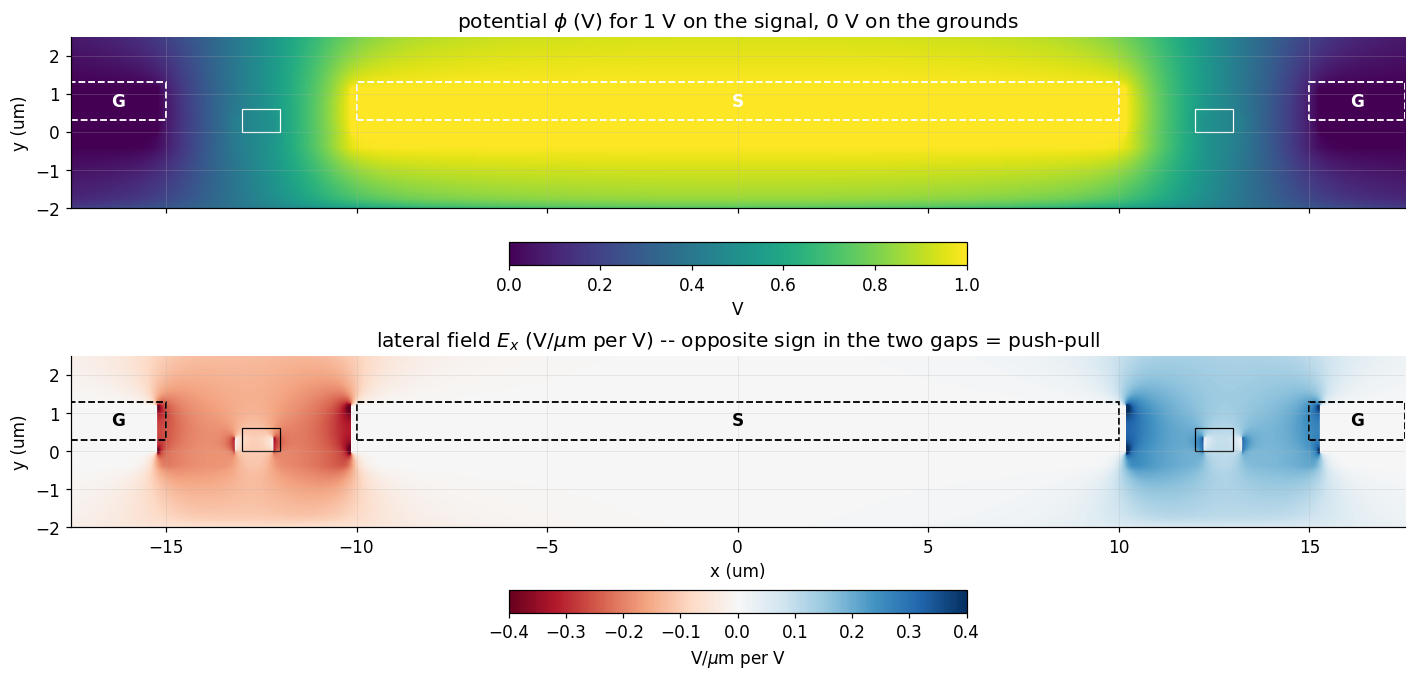

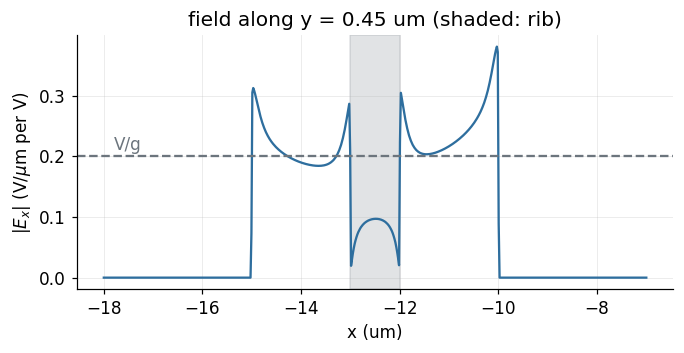

In [11]:
# 5.5 The real structure: potential and lateral field around the gaps.
# Equal aspect; dashed outlines mark the gold electrodes (S = signal, G = ground).
fld = es.solve_field(electrical, voltage=1.0)
print(f"grid: {len(fld.x_um)} x {len(fld.y_um)} nodes; C = {fld.capacitance_F_per_m * 1e12:.1f} pF/m")
XW, Y0, Y1 = 17.5, -2.0, 2.5
xs, ys = fld.xc_um, fld.yc_um
sel_x = (xs > -XW) & (xs < XW); sel_y = (ys > Y0) & (ys < Y1)

def outline_electrodes(a, color):
    """Dashed outline + label for each electrode inside the plotted window."""
    for name, lab in (("ground_left", "G"), ("signal", "S"), ("ground_right", "G")):
        x0, x1 = lay[name]
        x0, x1 = max(x0, -XW), min(x1, XW)
        a.add_patch(Rectangle((x0, slab_t), x1 - x0, electrical["metal_um"], fill=False, ec=color, ls="--", lw=1.2))
        a.text((x0 + x1) / 2, slab_t + electrical["metal_um"] / 2, lab, color=color, ha="center", va="center",
               fontsize=11, fontweight="bold")
    for c in lay["wg_centers"]:
        a.add_patch(Rectangle((c - optical["rib_width_um"] / 2, 0), optical["rib_width_um"], optical["film_um"],
                              fill=False, ec=color, lw=0.8))

fig, axs = plt.subplots(2, 1, figsize=(13, 6.6), sharex=True)
phi_win = fld.phi[np.ix_((fld.y_um > Y0) & (fld.y_um < Y1), (fld.x_um > -XW) & (fld.x_um < XW))]
im = axs[0].imshow(phi_win, origin="lower", extent=(-XW, XW, Y0, Y1), aspect="equal", cmap=style.CMAP_DENSITY)
axs[0].set_title(r"potential $\phi$ (V) for 1 V on the signal, 0 V on the grounds")
plt.colorbar(im, ax=axs[0], orientation="horizontal", fraction=0.08, pad=0.12, label="V")
outline_electrodes(axs[0], "w")
Ex = fld.Ex[np.ix_(sel_y, sel_x)] * 1e-6        # V/um
im = axs[1].imshow(Ex, origin="lower", extent=(-XW, XW, Y0, Y1), aspect="equal", cmap=style.CMAP_FIELD, vmin=-0.4, vmax=0.4)
axs[1].set_title(r"lateral field $E_x$ (V/$\mu$m per V) -- opposite sign in the two gaps = push-pull")
plt.colorbar(im, ax=axs[1], orientation="horizontal", fraction=0.08, pad=0.22, label=r"V/$\mu$m per V")
outline_electrodes(axs[1], "k")
for a in axs:
    a.set_ylabel("y (um)")
axs[1].set_xlabel("x (um)"); plt.tight_layout(); plt.show()

# Lateral cut through the middle of the left rib: field inside LN vs the V/g reference.
f_ex = fld.interpolator("Ex")
xl = np.linspace(-18, -7, 600)
yl = 0.45   # mid-height of the rib (between the slab top at 0.3 and the rib top at 0.6)
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(xl, -f_ex(np.stack([np.full_like(xl, yl), xl], -1)) * 1e-6, color=style.COLOR_STEEL)
ax.axhline(1 / electrical["gap_um"], color=style.COLOR_REFERENCE, ls="--"); ax.text(-17.8, 1 / electrical["gap_um"] + 0.01, "V/g", color=style.COLOR_REFERENCE)
c0 = lay["wg_centers"][0]
ax.axvspan(c0 - optical["rib_width_um"] / 2, c0 + optical["rib_width_um"] / 2, color=style.COLOR_REFERENCE, alpha=0.2)
ax.set_xlabel("x (um)"); ax.set_ylabel(r"$|E_x|$ (V/$\mu$m per V)"); ax.set_title(f"field along y = {yl} um (shaded: rib)")
plt.show()

In [12]:
# 5.6 Grid convergence of the capacitance and of the field at the waveguide center.
for h in (0.05, 0.025, 0.0125):
    s = es.solve_field({**electrical, "h_fine_um": h})
    e_c = s.interpolator("Ex")([[0.45, lay["wg_centers"][0]]])[0]
    print(f"h_fine = {h:6.4f} um: C = {s.capacitance_F_per_m * 1e12:8.3f} pF/m, Ex(wg center) = {e_c * 1e-6:+.4f} V/um")

h_fine = 0.0500 um: C =  173.255 pF/m, Ex(wg center) = -0.0975 V/um


h_fine = 0.0250 um: C =  173.158 pF/m, Ex(wg center) = -0.0970 V/um


h_fine = 0.0125 um: C =  173.113 pF/m, Ex(wg center) = -0.0967 V/um


## 6. Electro-optic overlap and $V_\pi L$

### 6.1 From a local index change to a modal index change

The electrode field is not uniform and the optical mode is not confined to
the LN, so the mode's effective index changes by a *weighted average* of the
local Pockels change. First-order perturbation theory for a waveguide mode
gives, at fixed frequency,

$$\Delta n_\mathrm{eff} = \frac{n_g}{2}\,
\frac{\displaystyle\int \Delta\varepsilon_{xx}(x,y)\,|E_x^\mathrm{opt}|^2\,dA}
     {\displaystyle\int \textstyle\sum_i \varepsilon_{ii}|E_i^\mathrm{opt}|^2\,dA},
\qquad \Delta\varepsilon_{xx}=-n_e^4\,r_{33}\,E_x^\mathrm{RF}(x,y)\ \text{inside LN only}.$$

(The $n_g/2$ prefactor converts the frequency shift at fixed $\beta$, which is
what the energy ratio gives, into an index shift at fixed frequency.) Check: in
a uniform medium the ratio is $\Delta\varepsilon/\varepsilon$ and $n_g=n$, giving
back $\Delta n = \Delta\varepsilon/(2n)$.

### 6.2 The overlap factor $\Gamma$

Design papers usually write the same result as

$$\frac{\partial n_\mathrm{eff}}{\partial V}=\frac{1}{2}\,n_e^3\,r_{33}\,\frac{\Gamma}{g},\qquad
\Gamma_\text{simple}=\frac{g}{V}\,\frac{\int_\mathrm{LN} E_x^\mathrm{RF}\,|\mathbf{E}^\mathrm{opt}|^2\,dA}{\int|\mathbf{E}^\mathrm{opt}|^2\,dA}.$$

$\Gamma$ asks: *compared with an ideal parallel-plate field $V/g$ filling the
whole mode, what fraction of the electro-optic effect do we get?* $\Gamma=1$
would mean every bit of the optical intensity sits in LN in a field $V/g$.
Real values are ~0.5-0.8: part of the mode is in the oxide/air (no Pockels
effect there) and the field inside the high-$\varepsilon$ LN is reduced
(section 5.3). The simple form is an approximation of 6.1 (it weights with
$|E|^2$ instead of $\varepsilon|E|^2$ and ignores $n_g\neq n_e$); both are
computed, and a third, independent number comes from re-solving the mode in
MPB with $\Delta\varepsilon(x,y)$ actually inserted.

### 6.3 Push-pull, $V_\pi$ and $V_\pi L$

In the GSG layout the field in the two gaps points in opposite directions, so
one arm's index rises while the other's falls by the same amount. Over an
electrode length $L$ the phase *difference* between the arms is

$$\Delta\varphi = \frac{2\pi}{\lambda}\,\big(2\,|\partial n_\mathrm{eff}/\partial V|\,V\big)\,L .$$

The half-wave voltage $V_\pi$ is the voltage giving $\Delta\varphi=\pi$:

$$V_\pi L=\frac{\lambda}{4\,|\partial n_\mathrm{eff}/\partial V|}=\frac{\lambda\,g}{2\,n_e^3\,r_{33}\,\Gamma}\quad(\text{push-pull}).$$

Without push-pull (one arm driven) it would be twice as large. $V_\pi L$ is the
modulator's efficiency figure of merit: a 2 V$\cdot$cm device needs 2 V over
1 cm, or 4 V over 0.5 cm.

### 6.4 The interferometer transfer function

With ideal 50:50 couplers, the bar/cross output powers are

$$T_\text{bar}=\sin^2\!\left(\tfrac{\Delta\varphi_0+\pi V/V_\pi}{2}\right),\qquad
T_\text{cross}=\cos^2\!\left(\tfrac{\Delta\varphi_0+\pi V/V_\pi}{2}\right)$$

(which port is "bar" depends on the coupler phases). For intensity modulation
(PAM4) the device is biased at **quadrature**, $T=1/2$, where the slope is
steepest and the curve is most nearly linear; a PAM4 swing of a fraction of
$V_\pi$ around that point keeps the four levels roughly equally spaced. The
**extinction ratio** (max/min power) is set by how close the couplers are to
50:50.

### 6.5 The gap trade-off

Narrowing the gap $g$ raises the field ($\propto1/g$) and lowers $V_\pi L$, but
brings the gold electrode edges closer to the optical mode, where metal absorbs
light. The sweep below reports, for each gap, $V_\pi L$ and the mode's relative
intensity at the electrode's bottom corner -- a proxy for metal loss (MPB here
has no metal, so the loss itself is not computed).

In [13]:
# 6.1/6.2 Overlap in both arms, with both formulas.
ov = [tm.overlap(mode, fld, optical, electrical, arm=a, r33=R33) for a in (0, 1)]
for o in ov:
    print(f"arm {o.arm}: Gamma_simple = {o.gamma_simple:+.3f}, Gamma_rigorous = {o.gamma_rigorous:+.3f}, "
          f"dn_eff/dV = {o.dn_dV_rigorous:+.3e} 1/V")
assert np.sign(ov[0].dn_dV_rigorous) == -np.sign(ov[1].dn_dV_rigorous), "arms are not push-pull"

arm 0: Gamma_simple = -0.497, Gamma_rigorous = -0.528, dn_eff/dV = +1.607e-05 1/V
arm 1: Gamma_simple = +0.497, Gamma_rigorous = +0.528, dn_eff/dV = -1.607e-05 1/V


> **STOP -- independent check.** The next cell inserts
> $\Delta\varepsilon_{xx}(x,y)=-n_e^4r_{33}E_x^\mathrm{RF}(x,y)\,V$ directly into
> MPB's permittivity (a material function over the LN blocks) at $\pm50$ V and
> re-solves the mode (~1 min). The large voltage only lifts the shift above the
> solver tolerance; the effect is linear. It should agree with the rigorous
> perturbation result of the cell above.

In [14]:
direct = tm.delta_neff_direct(fld, optical, electrical, voltage=50.0, arm=0, r33=R33)
rel = direct["dn_dV"] / ov[0].dn_dV_rigorous - 1
print(f"direct MPB re-solve : dn_eff/dV = {direct['dn_dV']:+.4e} 1/V")
print(f"perturbation theory : dn_eff/dV = {ov[0].dn_dV_rigorous:+.4e} 1/V   -> difference {100 * rel:+.2f} %")
print(f"simple Gamma formula: dn_eff/dV = {ov[0].dn_dV_simple:+.4e} 1/V   -> difference {100 * (ov[0].dn_dV_simple / direct['dn_dV'] - 1):+.2f} %")
DIRECT_TOL = 0.02
assert abs(rel) < DIRECT_TOL

direct MPB re-solve : dn_eff/dV = +1.6101e-05 1/V
perturbation theory : dn_eff/dV = +1.6072e-05 1/V   -> difference +0.18 %
simple Gamma formula: dn_eff/dV = +1.5121e-05 1/V   -> difference -6.08 %


Gamma = 0.528
V_pi L (push-pull) = 2.10 V*cm   with r33 = 30.9 pm/V
V_pi L (push-pull) = 2.41 V*cm   with r33 = 26.9 pm/V (Nature Materials 2025)
reported TFLN devices: ~1.7-2.3 V*cm (see section 1.1 sources)


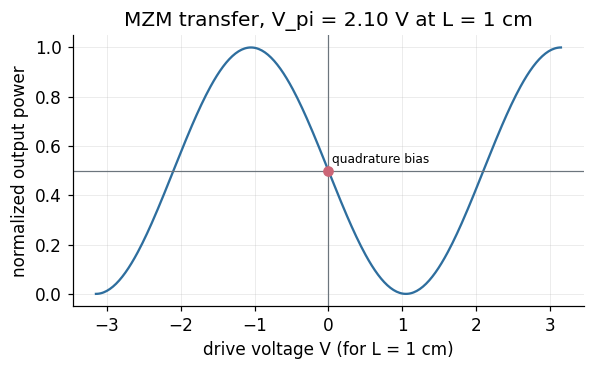

In [15]:
# 6.3 V_pi L for both r33 values.
DN_DV = abs(ov[0].dn_dV_rigorous)
VPI_L = tm.vpi_l_V_cm(DN_DV, WL0)
VPI_L_r269 = VPI_L * tm.R33_CLASSIC_M_PER_V / tm.R33_NATMAT2025_M_PER_V
GAMMA = abs(ov[0].gamma_rigorous)
print(f"Gamma = {GAMMA:.3f}")
print(f"V_pi L (push-pull) = {VPI_L:.2f} V*cm   with r33 = 30.9 pm/V")
print(f"V_pi L (push-pull) = {VPI_L_r269:.2f} V*cm   with r33 = 26.9 pm/V (Nature Materials 2025)")
print("reported TFLN devices: ~1.7-2.3 V*cm (see section 1.1 sources)")

# 6.4 Transfer function for a 1 cm electrode, biased at quadrature.
V = np.linspace(-1.5, 1.5, 301) * VPI_L
T = np.cos((np.pi / 2 + np.pi * V / VPI_L) / 2) ** 2
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(V, T, color=style.COLOR_STEEL)
ax.axvline(0, color=style.COLOR_REFERENCE, lw=0.8); ax.axhline(0.5, color=style.COLOR_REFERENCE, lw=0.8)
ax.plot(0, 0.5, "o", color=style.COLOR_ROSE); ax.text(0.05, 0.53, "quadrature bias", fontsize=8)
ax.set_xlabel("drive voltage V (for L = 1 cm)"); ax.set_ylabel("normalized output power")
ax.set_title(f"MZM transfer, V_pi = {VPI_L:.2f} V at L = 1 cm"); plt.show()

gap 3.0 um: Gamma = 0.568, V_pi L = 1.17 V*cm, |E|^2 at electrode corner = 1.1e-04 of peak


gap 4.0 um: Gamma = 0.547, V_pi L = 1.62 V*cm, |E|^2 at electrode corner = 3.8e-06 of peak


gap 5.0 um: Gamma = 0.528, V_pi L = 2.10 V*cm, |E|^2 at electrode corner = 2.4e-07 of peak


gap 6.0 um: Gamma = 0.510, V_pi L = 2.61 V*cm, |E|^2 at electrode corner = 9.8e-08 of peak


gap 7.0 um: Gamma = 0.494, V_pi L = 3.14 V*cm, |E|^2 at electrode corner = 4.2e-08 of peak


gap 8.0 um: Gamma = 0.476, V_pi L = 3.72 V*cm, |E|^2 at electrode corner = 4.7e-09 of peak


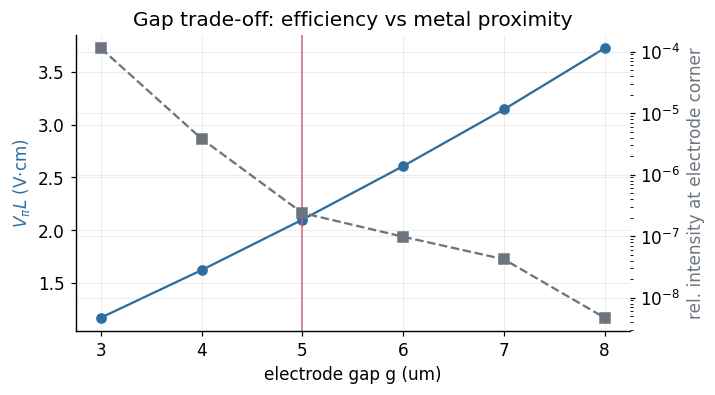

In [16]:
# 6.5 Gap sweep: V_pi L vs relative mode intensity at the electrode corner.
GAPS = [3.0, 4.0, 5.0, 6.0, 7.0, 8.0]
sweep = []
for g in GAPS:
    op_g, el_g = tm.combined_params(optical, {**electrical, "gap_um": g})
    m_g = tw.solve_mode(op_g)
    f_g = es.solve_field(el_g)
    o_g = tm.overlap(m_g, f_g, op_g, el_g, arm=0, r33=R33)
    edge = tw.mode_intensity_at(m_g, g / 2, slab_t)
    sweep.append((g, tm.vpi_l_V_cm(o_g.dn_dV_rigorous, WL0), abs(o_g.gamma_rigorous), edge))
    print(f"gap {g:.1f} um: Gamma = {abs(o_g.gamma_rigorous):.3f}, V_pi L = {sweep[-1][1]:.2f} V*cm, "
          f"|E|^2 at electrode corner = {edge:.1e} of peak")
sweep = np.array(sweep)
fig, ax1 = plt.subplots(figsize=(6.5, 3.5))
ax1.plot(sweep[:, 0], sweep[:, 1], "o-", color=style.COLOR_STEEL); ax1.set_ylabel(r"$V_\pi L$ (V$\cdot$cm)", color=style.COLOR_STEEL)
ax2 = ax1.twinx(); ax2.semilogy(sweep[:, 0], sweep[:, 3], "s--", color=style.COLOR_REFERENCE)
ax2.set_ylabel("rel. intensity at electrode corner", color=style.COLOR_REFERENCE)
ax1.axvline(electrical["gap_um"], color=style.COLOR_ROSE, lw=1)
ax1.set_xlabel("electrode gap g (um)"); ax1.set_title("Gap trade-off: efficiency vs metal proximity"); plt.show()

The intensity at the electrode corner falls by orders of magnitude per micron
of gap while $V_\pi L$ grows only linearly; a 5 $\mu$m gap keeps the metal in
the far tail of the mode, the common choice in reported TFLN devices.

**Key points.** (i) $\Gamma$ is computed three ways and the rigorous
perturbation result matches a direct MPB re-solve. (ii) $V_\pi L$ lands in the
range reported for real TFLN devices. (iii) Push-pull halves $V_\pi L$; the gap
trades efficiency against metal absorption.

## 7. 50:50 directional coupler in TFLN effective indices

The splitter and combiner are `coupler.py`'s directional coupler, used
unmodified but with TFLN effective indices. The index contrast is now only
about 0.2 (versus 1.26 for the toolkit's 2.7/1.44 guides), so the mode spreads
further: the gap is wider, and the S-bends are longer and gentler.

**Seed from supermodes.** Two identical coupled guides support an even and an
odd supermode with slightly different indices. Light launched in one guide is
their superposition, and power beats fully across after
$L_\times=\lambda/\big(2(n_\text{even}-n_\text{odd})\big)$; a 3 dB split needs
$L_{50}=L_\times/2$. The S-bends add some coupling of their own, so this
straight-section estimate is only a seed; the FDTD runs bracket it and
interpolate to $T_\text{cross}=0.5$, the same discipline as
`06_directional_coupler.ipynb`.

gap 0.5 um: n_even - n_odd = 1.01e-02 -> L_50 seed = 33.5 um
gap 0.6 um: n_even - n_odd = 7.16e-03 -> L_50 seed = 47.1 um
gap 0.8 um: n_even - n_odd = 3.62e-03 -> L_50 seed = 93.2 um
gap 1.0 um: n_even - n_odd = 1.83e-03 -> L_50 seed = 184.6 um
chosen gap 0.6 um, seed L_50 = 47.1 um


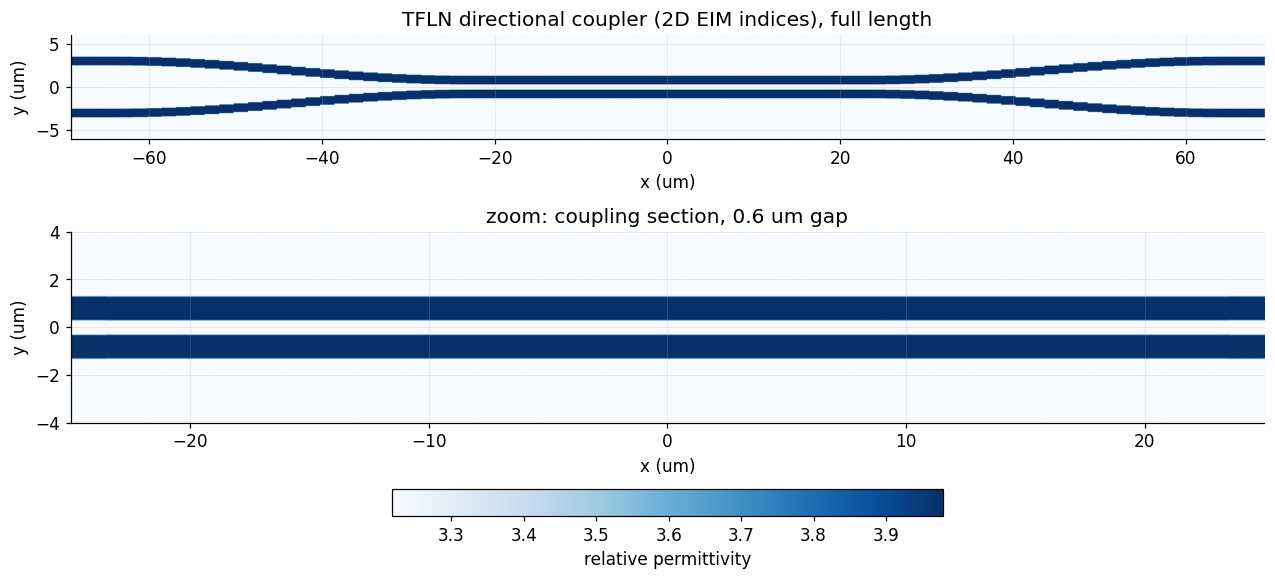

In [17]:
# Supermode seed vs gap (cheap: Meep's own eigenmode solver on a 1D cross-section).
for g in (0.5, 0.6, 0.8, 1.0):
    s = tm.supermode_coupling_length_um(eim["core_index"], eim["clad_index"], optical["rib_width_um"], g, WL0)
    print(f"gap {g:.1f} um: n_even - n_odd = {s['n_even'] - s['n_odd']:.2e} -> L_50 seed = {s['L_50_um']:.1f} um")
CPL_GAP = 0.6
seed = tm.supermode_coupling_length_um(eim["core_index"], eim["clad_index"], optical["rib_width_um"], CPL_GAP, WL0)["L_50_um"]
cp_base = tm.coupler_params(eim["core_index"], eim["clad_index"], gap_um=CPL_GAP, wg_width_um=optical["rib_width_um"])
print(f"chosen gap {CPL_GAP} um, seed L_50 = {seed:.1f} um")
pm = coupler.get_permittivity_map({**cp_base, "coupling_length_um": seed})

# Whole coupler at true (equal) aspect, then a zoom on the coupling region, which is
# where the 0.6 um gap is resolvable. One shared horizontal colorbar.
fig, axs = plt.subplots(2, 1, figsize=(14, 6.5), gridspec_kw=dict(height_ratios=[1, 1.4]))
for a, xlim, title in ((axs[0], None, "TFLN directional coupler (2D EIM indices), full length"),
                       (axs[1], (-25, 25), "zoom: coupling section, 0.6 um gap")):
    im = a.imshow(pm.eps.T, origin="lower", extent=pm.extent_um, cmap=style.CMAP_PERMITTIVITY_BASELINE, aspect="equal")
    if xlim: a.set_xlim(*xlim); a.set_ylim(-4, 4)
    a.set_title(title); a.set_xlabel("x (um)"); a.set_ylabel("y (um)")
fig.colorbar(im, ax=axs, orientation="horizontal", fraction=0.05, pad=0.12, label="relative permittivity")
plt.show()

> **STOP -- the next cell runs FDTD.** Three `coupler.simulate_baseline` runs
> (each launches from both inputs) at lengths bracketing the seed, then one
> validation run at the interpolated 50:50 length. Expect several hours on one
> core. Check the energy/reciprocity/passivity results printed for each run.

In [18]:
# S-bends add coupling, so 50:50 sits below the seed. Each length is nudged by at most
# half a pixel so the output mode monitors sit mid-pixel -- see
# tfln_mzm.monitor_safe_length for why a monitor exactly on a grid line at coupler.py's
# S-bend/lead junction corrupts the mode-coefficient measurement.
L_TRIAL = [tm.monitor_safe_length(cp_base, f * seed) for f in (0.5, 0.7, 0.9)]
trial, trial_ok = {}, {}
for L in L_TRIAL:
    t0 = time.time()
    r = coupler.simulate_baseline({**cp_base, "coupling_length_um": L})
    i0 = int(np.argmin(np.abs(r.wavelengths_um - WL0)))
    chk = coupler.run_all_checks(r)
    trial[L], trial_ok[L] = r, chk["passed"]
    print(f"L = {L:6.3f} um: T_cross(wl0) = {r.T_cross[i0]:.3f}, T_through = {r.T_through[i0]:.3f}, "
          f"checks passed = {chk['passed']}  ({(time.time() - t0) / 60:.1f} min)")

L = 23.550 um: T_cross(wl0) = 0.339, T_through = 0.655, checks passed = True  (16.0 min)


L = 32.983 um: T_cross(wl0) = 0.493, T_through = 0.499, checks passed = True  (18.3 min)


L = 42.383 um: T_cross(wl0) = 0.647, T_through = 0.344, checks passed = True  (19.4 min)


interpolated 50:50 length: 33.38 um (seed was 47.1 um)


validated: T_cross = 0.500, T_through = 0.493, R = 3.2e-05, loss = 0.007
{
 "energy_conservation": {
  "max_deviation_in_top": 0.0,
  "max_deviation_in_bot": 0.0,
  "max_deviation": 0.0,
  "max_expected_loss": 0.05,
  "tolerance": 0.03,
  "passed": true
 },
 "reciprocity": {
  "max_diff_through": 0.0008154035345288024,
  "max_diff_cross": 0.0009663739191170806,
  "max_diff_reflect": 1.449086003267922e-06,
  "max_diff": 0.0009663739191170806,
  "tolerance": 0.03,
  "passed": true
 },
 "passivity": {
  "max_power_fraction": 0.6083368772759714,
  "tolerance": 0.01,
  "passed": true
 },
 "passed": true
}


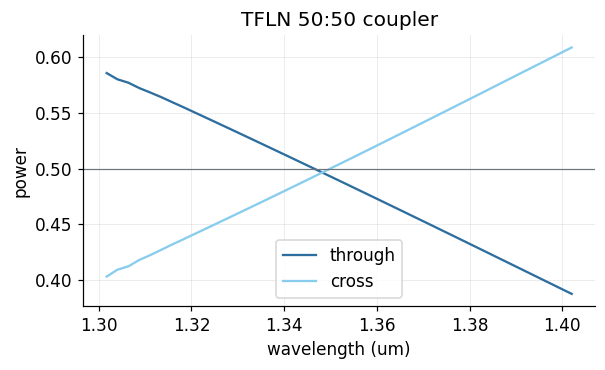

In [19]:
# Interpolate T_cross(wl0) = 0.5 over the trials that passed every physical check,
# then re-simulate there. The 50:50 point must be bracketed, not extrapolated.
good = [L for L in L_TRIAL if trial_ok[L]]
assert len(good) >= 2, "fewer than two valid coupler trials"
Ls = np.array(good)
Tc = np.array([trial[L].T_cross[int(np.argmin(np.abs(trial[L].wavelengths_um - WL0)))] for L in good])
order = np.argsort(Ls)
Ls, Tc = Ls[order], Tc[order]
assert Tc.min() < 0.5 < Tc.max(), "the 50:50 point is not bracketed by the valid trials"
k = int(np.nonzero((Tc[:-1] - 0.5) * (Tc[1:] - 0.5) <= 0)[0][0])   # first bracketing pair
(t_a, l_a), (t_b, l_b) = sorted(zip(Tc[k:k + 2], Ls[k:k + 2]))       # np.interp needs ascending x
L50 = tm.monitor_safe_length(cp_base, float(np.interp(0.5, [t_a, t_b], [l_a, l_b])))
print(f"interpolated 50:50 length: {L50:.2f} um (seed was {seed:.1f} um)")
cp = {**cp_base, "coupling_length_um": L50}
cpl = coupler.simulate_baseline(cp)
cpl_checks = coupler.run_all_checks(cpl)
i0 = int(np.argmin(np.abs(cpl.wavelengths_um - WL0)))
print(f"validated: T_cross = {cpl.T_cross[i0]:.3f}, T_through = {cpl.T_through[i0]:.3f}, "
      f"R = {cpl.R_reflect[i0]:.1e}, loss = {1 - cpl.T_cross[i0] - cpl.T_through[i0] - cpl.R_reflect[i0]:.3f}")
print(json.dumps(cpl_checks, indent=1, default=float))
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(cpl.wavelengths_um, cpl.T_through, color=style.COLOR_STEEL, label="through")
ax.plot(cpl.wavelengths_um, cpl.T_cross, color=style.COLOR_CYCLE[1], label="cross")
ax.axhline(0.5, color=style.COLOR_REFERENCE, lw=0.8); ax.set_xlabel("wavelength (um)"); ax.set_ylabel("power")
ax.legend(); ax.set_title("TFLN 50:50 coupler"); plt.show()

In [20]:
CPL_STEM = "../data/sparams/tfln_mzm/coupler/tfln_coupler_50_50"
coupler.save_artifact(CPL_STEM, cpl, {
    "component": "tfln_coupler", "coupling_length_um": L50, "gap_um": CPL_GAP,
    "core_index": cp["core_index"], "clad_index": cp["clad_index"], "wg_width_um": cp["wg_width_um"],
    "sbend_len_um": cp["sbend_len_um"], "wide_sep_um": cp["wide_sep_um"], "resolution": cp["resolution"],
    "polarization": "TE (eig_parity=mp.TE)", "validation": cpl_checks,
})
print("saved:", CPL_STEM)

saved: ../data/sparams/tfln_mzm/coupler/tfln_coupler_50_50


## 8. The full interferometer in 2D FDTD

**What this checks, and what it does not.** A real arm is ~1 cm long, which a
2D FDTD cell cannot afford. As in `08_mzm.ipynb`, the arm is shortened and the
index change exaggerated so that the *phase* is the same: what matters for the
interferometer is $\Delta\varphi = k_0\,\Delta n_\mathrm{eff}\,L$, not $\Delta n$
and $L$ separately. `mzm.simulate` (unmodified) raises the core index of the
two arms by $\pm\Delta n/2$; with the computed phase-response factor $p$,

$$\Delta\varphi = \frac{2\pi}{\lambda_0}\,p\,\Delta n\,L_\text{plateau},$$

and the arm is sized so that $\Delta n_{V_\pi}$ gives $\pi$. The run verifies
that the TFLN couplers and arms convert phase into intensity as the SAX model
in section 11 assumes. The volts-to-phase step is the cross-section physics of
section 6, which no 2D simulation could capture.

plateau length = 188.0 um, arm length = 212.0 um


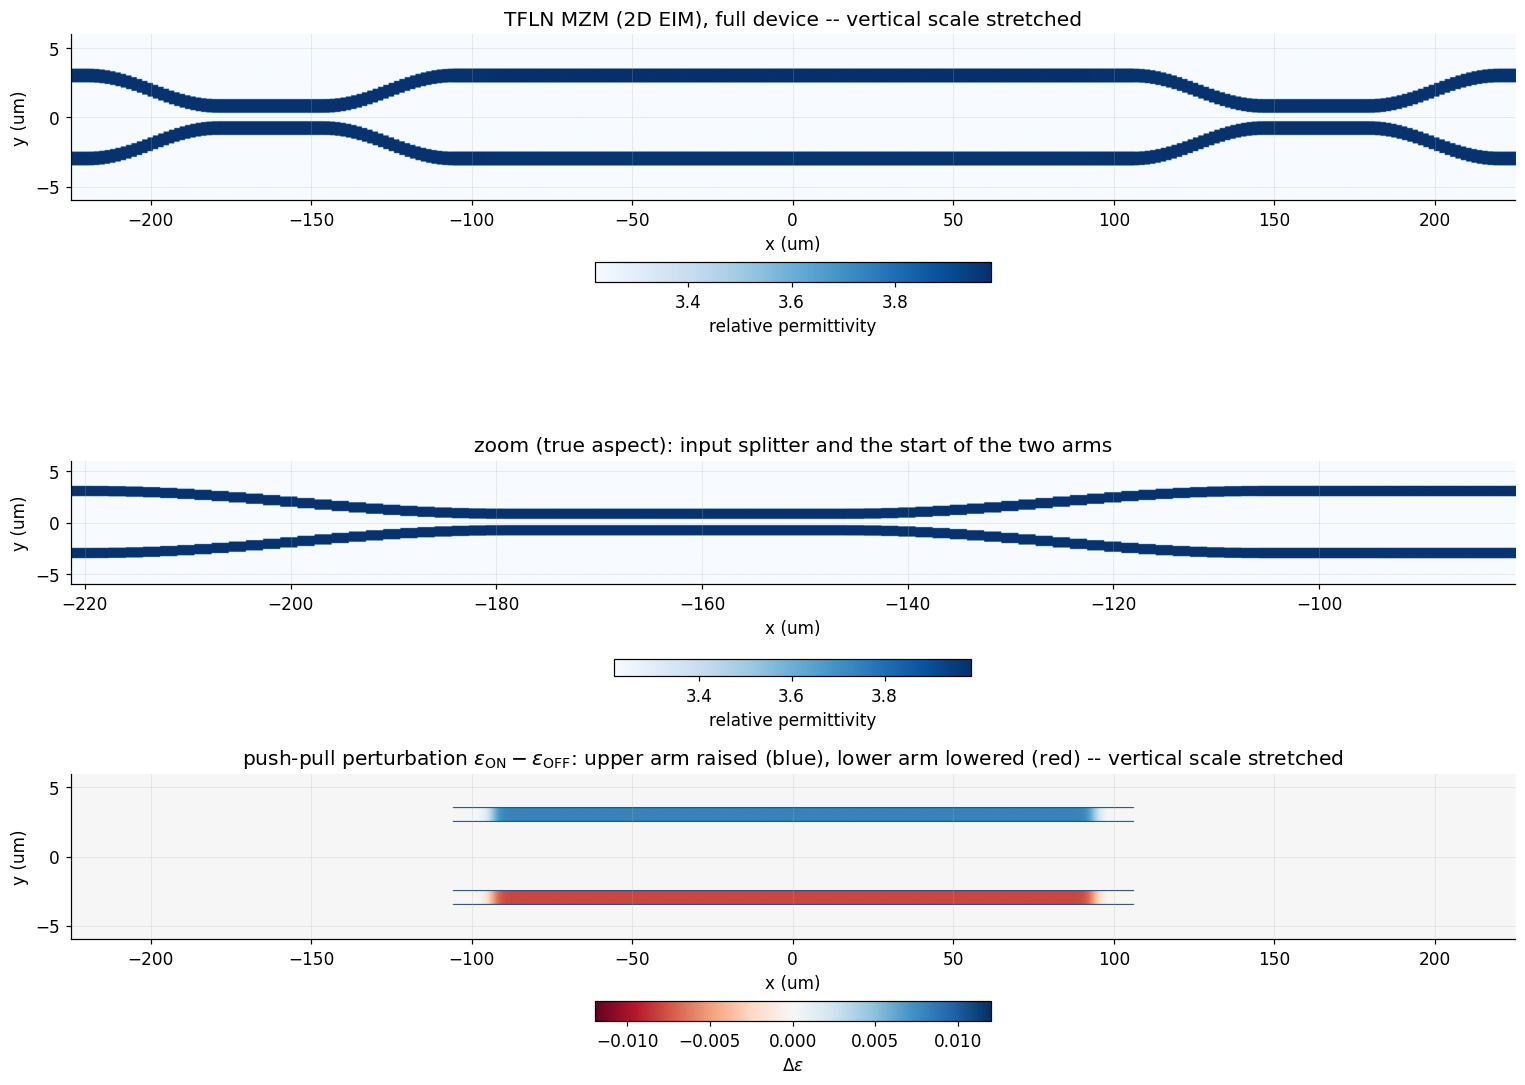

In [21]:
DN_VPI_MEEP = 0.004   # exaggerated push-pull core-index difference giving pi on a ~200 um plateau
mp_params = tm.mzm_meep_params(cp, delta_n_vpi=DN_VPI_MEEP, phase_factor=PHASE_FACTOR)
print(f"plateau length = {mzm.plateau_length_um(mp_params):.1f} um, arm length = {mzm.arm_length_um(mp_params):.1f} um")
pmap = mzm.get_permittivity_map(mp_params, -DN_VPI_MEEP / 2, DN_VPI_MEEP / 2)
pmap0 = mzm.get_permittivity_map(mp_params, 0.0, 0.0)

# The device is ~450 um long but only ~11 um tall, so at true aspect it is a hairline.
# Panel 1: whole device with the vertical axis stretched (aspect="auto").
# Panel 2: true-aspect zoom on the splitter. Panel 3: the push-pull perturbation itself,
# eps(ON) - eps(OFF), which is invisible on the permittivity colour scale (Delta n = 0.002
# per arm vs a core/cladding contrast of ~0.2).
ext = pmap.extent_um
fig, axs = plt.subplots(3, 1, figsize=(14, 10), gridspec_kw=dict(height_ratios=[1, 1.2, 1]))
im = axs[0].imshow(pmap.eps.T, origin="lower", extent=ext, cmap=style.CMAP_PERMITTIVITY_BASELINE, aspect="auto")
axs[0].set_title("TFLN MZM (2D EIM), full device -- vertical scale stretched")
fig.colorbar(im, ax=axs[0], orientation="horizontal", fraction=0.08, pad=0.25, label="relative permittivity")
dom = mzm._compute_domain(mp_params)
xc1 = dom["x_c1_center"]; half = dom["coupler_device_len"] / 2
im = axs[1].imshow(pmap.eps.T, origin="lower", extent=ext, cmap=style.CMAP_PERMITTIVITY_BASELINE, aspect="equal")
axs[1].set_xlim(xc1 - half - 2, xc1 + half + 25); axs[1].set_ylim(ext[2], ext[3])
axs[1].set_title("zoom (true aspect): input splitter and the start of the two arms")
fig.colorbar(im, ax=axs[1], orientation="horizontal", fraction=0.06, pad=0.25, label="relative permittivity")
d_eps = (pmap.eps - pmap0.eps).T
# Inside each arm the change is eps(n + dn/2) - eps(n) ~ n * dn ~ 0.008; the colour scale is
# set to that, so the arms read clearly (a few waveguide-edge pixels, where the perturbed and
# unperturbed geometries are smoothed slightly differently, saturate).
v = 1.5 * ((mp_params["core_index"] + DN_VPI_MEEP / 2) ** 2 - mp_params["core_index"] ** 2)
im = axs[2].imshow(d_eps, origin="lower", extent=ext, cmap=style.CMAP_FIELD, vmin=-v, vmax=v, aspect="auto")
axs[2].set_title(r"push-pull perturbation $\varepsilon_\mathrm{ON}-\varepsilon_\mathrm{OFF}$: upper arm raised (blue), lower arm lowered (red) -- vertical scale stretched")
fig.colorbar(im, ax=axs[2], orientation="horizontal", fraction=0.08, pad=0.25, label=r"$\Delta\varepsilon$")
for a in axs:
    a.set_xlabel("x (um)"); a.set_ylabel("y (um)")
plt.tight_layout(); plt.show()

> **STOP -- the next cells run FDTD (hours on a first run; saved results with the same
> parameters are reloaded).** First the full 4-port baseline at
> the $V_\pi$ point (both inputs excited, strict checks), then a single-input
> sweep of $\Delta n$.

In [22]:
# Full 4-port baseline at the V_pi point, or the saved result of an identical run
# (load_or_simulate checks every recorded parameter, the push-pull point and n_freq).
t0 = time.time()
BASE_STEM = "../data/sparams/tfln_mzm/baseline/tfln_mzm_vpi"
mzm_base = mzm.load_or_simulate(mp_params, -DN_VPI_MEEP / 2, DN_VPI_MEEP / 2, BASE_STEM, dual_excitation=True)
mzm_checks = mzm.run_all_checks(mzm_base)
i0 = int(np.argmin(np.abs(mzm_base.wavelengths_um - WL0)))
print(f"({(time.time() - t0) / 60:.1f} min) at Delta n = Delta n_Vpi: |S31|^2 = {abs(mzm_base.S31[i0])**2:.3f}, "
      f"|S41|^2 = {abs(mzm_base.S41[i0])**2:.3f}")
print(json.dumps(mzm_checks, indent=1, default=float))
mzm.save_artifact(BASE_STEM, mzm_base,
                  {"component": "tfln_mzm_2d", "delta_n_vpi": DN_VPI_MEEP, "phase_factor": PHASE_FACTOR,
                   "simulation_params": mp_params, "validation": mzm_checks})


loaded cached FDTD result: ../data/sparams/tfln_mzm/baseline/tfln_mzm_vpi
(0.0 min) at Delta n = Delta n_Vpi: |S31|^2 = 0.988, |S41|^2 = 0.001
{
 "energy_conservation": {
  "max_deviation_port1": 0.0,
  "max_deviation_port2": 0.0,
  "max_deviation": 0.0,
  "max_expected_loss": 0.05,
  "tolerance": 0.03,
  "passed": true
 },
 "reciprocity": {
  "max_diff": 5.611280196201064e-05,
  "tolerance": 0.03,
  "passed": true
 },
 "passivity": {
  "max_power_fraction": 0.989735771465504,
  "tolerance": 0.01,
  "passed": true
 },
 "passed": true
}


In [23]:
# Single-input Delta n sweep (0, 1/3 and 2/3 of Delta n_Vpi); the V_pi point is the baseline above.
DN_SWEEP = [0.0, DN_VPI_MEEP / 3, 2 * DN_VPI_MEEP / 3]
sweep_res = {}
for dn in DN_SWEEP:
    t0 = time.time()
    stem = f"../data/sparams/tfln_mzm/sweep/tfln_mzm_dn{dn:.5f}"
    r = mzm.load_or_simulate(mp_params, -dn / 2, dn / 2, stem)
    sweep_res[dn] = r
    mzm.save_artifact(stem, r, {"component": "tfln_mzm_2d", "delta_n": dn, "phase_factor": PHASE_FACTOR,
                                "simulation_params": mp_params})
    print(f"Delta n = {dn:.5f}: |S31|^2 = {abs(r.S31[i0])**2:.3f}, |S41|^2 = {abs(r.S41[i0])**2:.3f} "
          f"({(time.time() - t0) / 60:.1f} min)")
sweep_res[DN_VPI_MEEP] = mzm_base


loaded cached FDTD result: ../data/sparams/tfln_mzm/sweep/tfln_mzm_dn0.00000
Delta n = 0.00000: |S31|^2 = 0.000, |S41|^2 = 0.989 (0.0 min)
loaded cached FDTD result: ../data/sparams/tfln_mzm/sweep/tfln_mzm_dn0.00133
Delta n = 0.00133: |S31|^2 = 0.255, |S41|^2 = 0.736 (0.0 min)
loaded cached FDTD result: ../data/sparams/tfln_mzm/sweep/tfln_mzm_dn0.00267
Delta n = 0.00267: |S31|^2 = 0.755, |S41|^2 = 0.235 (0.0 min)


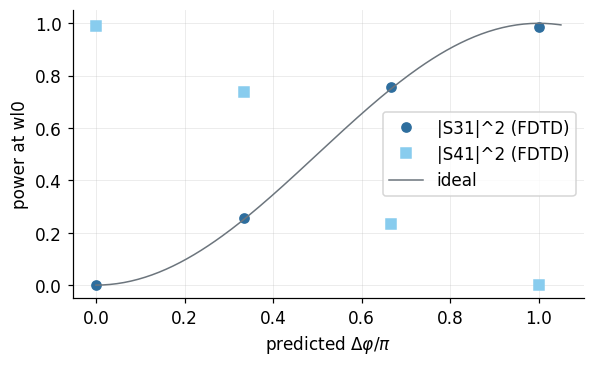

Delta n = 0.00133: arg(S31/S41) = +0.004 pi -> realized 0.338 pi (predicted 0.333 pi)
Delta n = 0.00267: arg(S31/S41) = +0.001 pi -> realized 0.676 pi (predicted 0.667 pi)
Delta n = 0.00400: arg(S31/S41) = -0.984 pi -> realized 1.015 pi (predicted 1.000 pi)
total output at V_pi point = 0.988
realized phase at the V_pi point: 1.015 pi (target 1)
realized phase-response factor = 0.911 (computed prior 0.898)


In [24]:
# Phase predicted from Delta n vs the measured bar/cross powers, and the
# phase-response factor actually realized at the V_pi point (no forcing).
dns = np.array(sorted(sweep_res))
Lp = mzm.plateau_length_um(mp_params)
dphi_pred = 2 * np.pi / WL0 * PHASE_FACTOR * dns * Lp
T31 = np.array([abs(sweep_res[d].S31[i0]) ** 2 for d in dns])
T41 = np.array([abs(sweep_res[d].S41[i0]) ** 2 for d in dns])
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(dphi_pred / np.pi, T31, "o", color=style.COLOR_STEEL, label="|S31|^2 (FDTD)")
ax.plot(dphi_pred / np.pi, T41, "s", color=style.COLOR_CYCLE[1], label="|S41|^2 (FDTD)")
ph = np.linspace(0, 1.05, 200)
T0 = T31[0]   # the zero-drive bar power fixes which port is "bar"
ax.plot(ph, T0 * np.cos(ph * np.pi / 2) ** 2 + (1 - T0) * np.sin(ph * np.pi / 2) ** 2, color=style.COLOR_REFERENCE, lw=1, label="ideal")
ax.set_xlabel(r"predicted $\Delta\varphi/\pi$"); ax.set_ylabel("power at wl0"); ax.legend(); plt.show()
# Realized phase at every drive point. The bar fraction |S31|^2 / (|S31|^2 + |S41|^2)
# is normalized by the total output, so the ~1 % coupler/propagation loss is not misread
# as a phase error. It gives sin^2(dphi/2), which cannot tell dphi from 2 pi - dphi; the
# complex ratio S31/S41 (proportional to tan(dphi/2) for identical couplers) can: its
# phase jumps by pi when dphi passes pi. The first driven point (dphi well below pi)
# sets the reference phase of that ratio.
ref_ratio_phase = np.angle(sweep_res[dns[1]].S31[i0] / sweep_res[dns[1]].S41[i0])
dphi_real = np.zeros(len(dns))
for j, d in enumerate(dns[1:], start=1):
    s31, s41 = sweep_res[d].S31[i0], sweep_res[d].S41[i0]
    theta = 2 * np.arcsin(np.sqrt(T31[j] / (T31[j] + T41[j])))
    flipped = np.cos(np.angle(s31 / s41) - ref_ratio_phase) < 0
    dphi_real[j] = 2 * np.pi - theta if flipped else theta
    print(f"Delta n = {d:.5f}: arg(S31/S41) = {np.angle(s31 / s41) / np.pi:+.3f} pi -> "
          f"realized {dphi_real[j] / np.pi:.3f} pi (predicted {dphi_pred[j] / np.pi:.3f} pi)")
print(f"total output at V_pi point = {T31[-1] + T41[-1]:.3f}")
PHASE_FACTOR_REALIZED = PHASE_FACTOR * dphi_real[-1] / np.pi
print(f"realized phase at the V_pi point: {dphi_real[-1] / np.pi:.3f} pi (target 1)")
print(f"realized phase-response factor = {PHASE_FACTOR_REALIZED:.3f} (computed prior {PHASE_FACTOR:.3f})")


## 9. Traveling-wave electrodes and electro-optic bandwidth

This section is the RF primer. It answers one question: **how fast can this
modulator be driven, and what sets the limit?**

### 9.1 Why the electrode is a transmission line

A lumped (capacitor-like) electrode charges through the 50 $\Omega$ driver:
its bandwidth is about $1/(2\pi R C_\text{total})$. A 1 cm electrode with
$\sim$150 pF/m has $C_\text{total}\approx1.5$ pF, giving only $\sim$2 GHz. Worse,
1 cm is comparable to the RF wavelength at tens of GHz (about 1.4 mm at
100 GHz), so the voltage is not even uniform along it.

The solution is a **traveling-wave electrode**: make the electrode a
transmission line terminated in its own impedance, feed the RF at the end where
light enters, and let the RF wave co-propagate with the light. Then the
capacitance is not "charged" as a whole; it is part of the line, and the limit
moves to how well the two waves stay together.

### 9.2 Transmission-line basics

A uniform line is described per unit length by an inductance $\mathcal{L}$
(H/m) and a capacitance $C$ (F/m). Voltage waves travel at
$v=1/\sqrt{\mathcal{L}C}$, i.e. with RF index $n_\mathrm{RF}=c/v$, and see a
characteristic impedance $Z_0=\sqrt{\mathcal{L}/C}$ -- the ratio of voltage to
current in a single traveling wave. If the line is terminated in $Z_L\neq Z_0$,
part of the wave reflects, with reflection coefficient
$\Gamma_L=(Z_L-Z_0)/(Z_L+Z_0)$.

**Quasi-TEM trick.** In a line whose conductors are surrounded by
dielectrics, $\mathcal{L}$ does not depend on the dielectrics (they are
non-magnetic). So one electrostatic solve with all dielectrics replaced by
vacuum gives $C_\text{air}$ and $\mathcal{L}=1/(c^2C_\text{air})$, and one with the
real dielectrics gives $C$. Then

$$n_\mathrm{RF}=\sqrt{\frac{C}{C_\text{air}}},\qquad Z_0=\frac{1}{c\sqrt{C\,C_\text{air}}}.$$

### 9.3 The three bandwidth limits

Write the line voltage as a forward wave plus a reflection from the load,
$V(z)=V^+\big(e^{-\gamma z}+\Gamma_L e^{-2\gamma L}e^{+\gamma z}\big)$ with
$\gamma=\alpha+j\omega n_\mathrm{RF}/c$. A photon that enters at time $t_0$
reaches $z$ at $t_0+z\,n_g/c$, so the phase it collects is

$$\Phi(\omega)\propto\int_0^L V(z)\,e^{\,j\omega n_g z/c}\,dz .$$

The **EO response** is $m(f)=|\Phi(f)|/|\Phi(0)|$ (`tfln_mzm.eo_response`). Three
effects make $m$ fall with frequency:

1. **Velocity mismatch.** If $n_\mathrm{RF}\neq n_g$, the photon slowly slips
   relative to the RF wave and sees a voltage whose sign eventually reverses.
   For a lossless matched line,
   $$m(f)=\left|\frac{\sin u}{u}\right|,\qquad u=\frac{\pi f L\,|n_\mathrm{RF}-n_g|}{c},$$
   which reaches $-3$ dB at $u=1.39$:
   $$f_{3\,\mathrm{dB}}\approx\frac{1.39\,c}{\pi\,L\,|n_\mathrm{RF}-n_g|}.$$
   Bulk LN modulators suffered badly here ($n_\mathrm{RF}\approx4.2$ vs
   $n_g\approx2.2$); in thin film most of the RF field is in air/oxide, which
   brings $n_\mathrm{RF}$ down near $n_g$ -- one of TFLN's main advantages.
2. **Conductor loss.** RF current flows in a thin "skin" of the metal, of
   depth $\delta=\sqrt{1/(\pi f\mu_0\sigma)}$ (0.25 $\mu$m in gold at 100 GHz),
   so the resistance rises as $\sqrt f$ and the voltage decays as
   $e^{-\alpha z}$ with $\alpha\propto\sqrt f$. With matched velocities and
   $\alpha L\gg1$, the photon effectively sees only the first $1/\alpha$ of
   the electrode. This is usually the dominant limit in TFLN.
3. **Impedance mismatch.** If $Z_0\neq50\ \Omega$, less voltage enters the line
   and part of it bounces back from the load. The back-travelling part is
   strongly velocity-mismatched (it moves against the light), so it mostly
   averages out.

**Conductor loss from the electrostatic solver.** Rather than assuming a
literature loss value, this notebook uses Wheeler's
*incremental-inductance rule*: if every metal surface is receded by $\delta n$
(as the field penetrates the skin), $\mathcal{L}$ grows by
$\delta\mathcal{L}$, and

$$\alpha_c=\frac{R_s}{2Z_0\,\mu_0}\,\frac{\partial\mathcal{L}}{\partial n},\qquad R_s=\frac{1}{\sigma\,\delta},$$

where $\partial\mathcal L/\partial n$ comes from two vacuum solves on one grid
(`tfln_electrostatics.conductor_loss`).
$R_s=\sqrt{\pi f\mu_0/\sigma}$ is the standard skin-effect form, valid once the skin
depth is smaller than the metal thickness (above ~6 GHz for 1 $\mu$m of gold);
below that the current spreads through the whole conductor and the model
underestimates the loss, so the response curves are accurate from a few GHz
upward. Dielectric loss of LN/SiO$_2$ and radiation into the substrate are not
included.

### 9.4 Bandwidth conventions

Papers quote an "EO 3 dB bandwidth" where $20\log_{10}m=-3$ dB -- the RF power
of the detected signal is down by half. Some quote the frequency where the
*optical* modulation depth is halved ($20\log_{10}m=-6$ dB), which looks almost
twice as large. This notebook uses the $-3$ dB electrical convention.

**How much bandwidth is needed?** As a rule of thumb (with DSP equalization),
EO bandwidth of roughly 0.5-0.7 x the symbol rate: 200 G/lane PAM4
(106 GBd) needs ~55-75 GHz, 400 G/lane (~212 GBd) needs >100 GHz.

### 9.5 The design trade-off

$V_\pi=V_\pi L/L$ falls as the electrode gets longer, but every bandwidth
limit above gets worse with $L$. The design question is therefore: *what is the
longest electrode (lowest $V_\pi$) that still meets the bandwidth target?*

C = 173.2 pF/m, C_air = 37.8 pF/m
n_RF = 2.141  vs optical n_g = 2.297 (dispersive)  -> mismatch -0.157
Z0 = 41.2 ohm
conductor loss at 100 GHz = 8.72 dB/cm (= 0.87 dB/cm/sqrt(GHz))


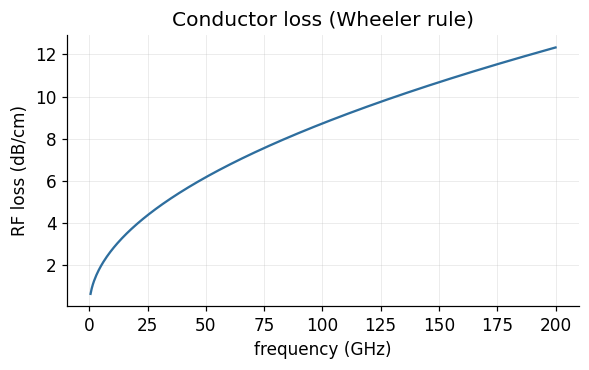

In [25]:
# 9.1 Line constants and conductor loss at the default stack (2 um BOX).
rf = es.rf_line_constants(electrical)
F = np.linspace(0.5e9, 200e9, 400)
loss = es.conductor_loss(electrical, F)
NG = ng["n_g_dispersive"]
print(f"C = {rf['C_F_per_m'] * 1e12:.1f} pF/m, C_air = {rf['C_air_F_per_m'] * 1e12:.1f} pF/m")
print(f"n_RF = {rf['n_rf']:.3f}  vs optical n_g = {NG:.3f} (dispersive)  -> mismatch {rf['n_rf'] - NG:+.3f}")
print(f"Z0 = {rf['Z0_ohm']:.1f} ohm")
i100 = int(np.argmin(np.abs(F - 100e9)))
print(f"conductor loss at 100 GHz = {loss['alpha_db_per_cm'][i100]:.2f} dB/cm "
      f"(= {loss['alpha_db_per_cm'][i100] / 10:.2f} dB/cm/sqrt(GHz))")
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(F / 1e9, loss["alpha_db_per_cm"], color=style.COLOR_STEEL)
ax.set_xlabel("frequency (GHz)"); ax.set_ylabel("RF loss (dB/cm)"); ax.set_title("Conductor loss (Wheeler rule)"); plt.show()

BOX 1.0 um: n_RF = 2.274, Z0 = 38.8 ohm, velocity-only f3dB at L = 1 cm: 565 GHz


BOX 1.5 um: n_RF = 2.199, Z0 = 40.2 ohm, velocity-only f3dB at L = 1 cm: 135 GHz


BOX 2.0 um: n_RF = 2.141, Z0 = 41.2 ohm, velocity-only f3dB at L = 1 cm: 85 GHz


BOX 3.0 um: n_RF = 2.056, Z0 = 42.9 ohm, velocity-only f3dB at L = 1 cm: 55 GHz


BOX 4.7 um: n_RF = 1.966, Z0 = 44.9 ohm, velocity-only f3dB at L = 1 cm: 40 GHz


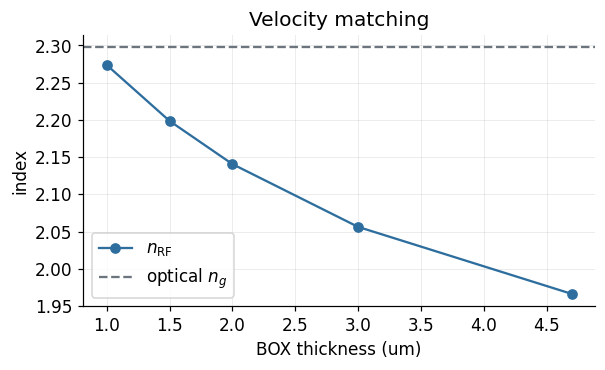

In [26]:
# 9.2 Velocity matching vs buried-oxide thickness: the Si handle (eps 11.7) pulls
# the RF index up as the BOX thins. (The optical mode is unaffected as long as the
# BOX stays thick enough to stop leakage into the Si -- not modeled here, so very
# thin BOX values are shown for the RF trend only.)
BOXES = [1.0, 1.5, 2.0, 3.0, 4.7]
box_rows = []
for b in BOXES:
    r_b = es.rf_line_constants({**electrical, "box_um": b})
    box_rows.append((b, r_b["n_rf"], r_b["Z0_ohm"]))
    print(f"BOX {b:3.1f} um: n_RF = {r_b['n_rf']:.3f}, Z0 = {r_b['Z0_ohm']:.1f} ohm, "
          f"velocity-only f3dB at L = 1 cm: {tm.velocity_mismatch_f3db_hz(0.01, r_b['n_rf'], NG) / 1e9:.0f} GHz")
box_rows = np.array(box_rows)
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(box_rows[:, 0], box_rows[:, 1], "o-", color=style.COLOR_STEEL, label=r"$n_\mathrm{RF}$")
ax.axhline(NG, color=style.COLOR_REFERENCE, ls="--", label=r"optical $n_g$")
ax.set_xlabel("BOX thickness (um)"); ax.set_ylabel("index"); ax.legend(); ax.set_title("Velocity matching"); plt.show()

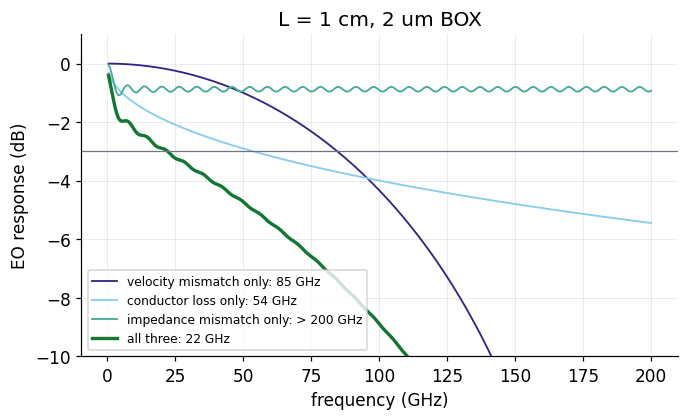

In [27]:
# 9.3 What limits the bandwidth at L = 1 cm? Each effect alone, then all together.
L_REF = 0.01
a = loss["alpha_np_per_m"]
cases = {
    "velocity mismatch only": dict(n_rf=rf["n_rf"], alpha=0 * a, z0=50.0),
    "conductor loss only": dict(n_rf=NG, alpha=a, z0=50.0),
    "impedance mismatch only": dict(n_rf=NG, alpha=0 * a, z0=rf["Z0_ohm"]),
    "all three": dict(n_rf=rf["n_rf"], alpha=a, z0=rf["Z0_ohm"]),
}
fig, ax = plt.subplots(figsize=(7, 3.8))
for (name, c), col in zip(cases.items(), style.COLOR_CYCLE):
    m = tm.eo_response(F, L_REF, c["n_rf"], NG, c["alpha"], c["z0"])
    f3 = tm.f3db_hz(F, m)
    f3_txt = f"{f3 / 1e9:.0f} GHz" if np.isfinite(f3) else f"> {F[-1] / 1e9:.0f} GHz"
    ax.plot(F / 1e9, 20 * np.log10(m), color=col, lw=2.2 if name == "all three" else 1.2, label=f"{name}: {f3_txt}")
ax.axhline(-3, color=style.COLOR_REFERENCE, lw=0.8)
ax.set_ylim(-10, 1); ax.set_xlabel("frequency (GHz)"); ax.set_ylabel("EO response (dB)")
ax.set_title("L = 1 cm, 2 um BOX"); ax.legend(fontsize=8); plt.show()

**Reading the combined curve.** The effects do not simply take the minimum of
the individual bandwidths. Impedance mismatch alone costs only a ripple of
just under 1 dB: at high frequency the far-end reflection is damped out, and
the line input settles at $V_s Z_0/(Z_0+Z_s)$ instead of the DC value
$V_s Z_L/(Z_L+Z_s)$. But the loss-limited response falls only slowly, so that
fixed ~1 dB offset moves the $-3$ dB crossing a long way down in frequency.
This is why practical TFLN electrodes are designed for both velocity
matching *and* $Z_0$ close to 50 $\Omega$, even though neither looks
critical on its own.

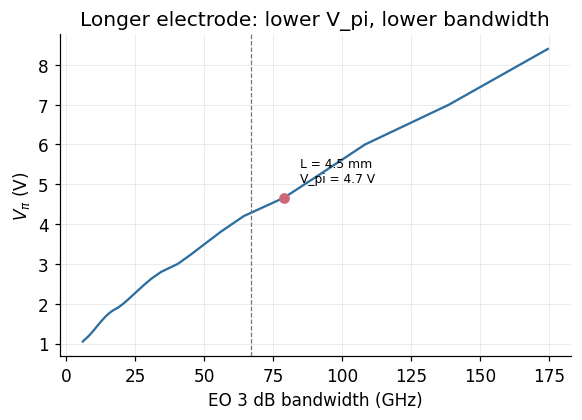

design: L = 4.5 mm, V_pi = 4.67 V, EO 3 dB bandwidth = 79 GHz


In [28]:
# 9.4 Trade-off: V_pi vs EO bandwidth as the electrode length varies, and the
# design point = longest electrode meeting the bandwidth target.
TARGET_F3DB_GHZ = 67.0     # 200 G/lane PAM4 class (rule of thumb, section 9.4)
LENGTHS_MM = np.round(np.arange(2.0, 20.01, 0.5), 2)
f3 = np.array([tm.f3db_hz(F, tm.eo_response(F, Lmm * 1e-3, rf["n_rf"], NG, a, rf["Z0_ohm"])) for Lmm in LENGTHS_MM])
vpi = VPI_L / (LENGTHS_MM / 10)
ok = f3 >= TARGET_F3DB_GHZ * 1e9
L_DESIGN_MM = float(LENGTHS_MM[ok].max())
F3_DESIGN = float(f3[LENGTHS_MM == L_DESIGN_MM][0])
VPI_DESIGN = VPI_L / (L_DESIGN_MM / 10)
fig, ax = plt.subplots(figsize=(6, 3.8))
ax.plot(f3 / 1e9, vpi, "-", color=style.COLOR_STEEL)
ax.plot(F3_DESIGN / 1e9, VPI_DESIGN, "o", color=style.COLOR_ROSE)
ax.annotate(f"L = {L_DESIGN_MM} mm\nV_pi = {VPI_DESIGN:.1f} V", (F3_DESIGN / 1e9, VPI_DESIGN), xytext=(10, 10), textcoords="offset points", fontsize=8)
ax.axvline(TARGET_F3DB_GHZ, color=style.COLOR_REFERENCE, ls="--", lw=0.8)
ax.set_xlabel("EO 3 dB bandwidth (GHz)"); ax.set_ylabel(r"$V_\pi$ (V)")
ax.set_title("Longer electrode: lower V_pi, lower bandwidth"); plt.show()
print(f"design: L = {L_DESIGN_MM} mm, V_pi = {VPI_DESIGN:.2f} V, EO 3 dB bandwidth = {F3_DESIGN / 1e9:.0f} GHz")

**Key points.** (i) In thin film the RF index sits close to the optical group
index, so velocity mismatch is a secondary limit; conductor loss is the main
one. (ii) A thinner BOX raises $n_\mathrm{RF}$ toward $n_g$ (at the cost of
optical leakage risk, not modeled here). (iii) The electrode length sets the
$V_\pi$-versus-bandwidth trade-off; the design point is the longest electrode
that still meets the bandwidth target.

## 10. Save design point

> **STOP -- this writes `data/design_points/tfln_mzm.yaml`**, the single source of
> truth the SAX model reads.

In [29]:
record = {
    "component": "tfln_mzm",
    "wl0_um": WL0,
    "parameters": {"optical": {k: v for k, v in optical.items()},
                   "electrical": {k: v for k, v in electrical.items() if k not in ("metal_inset_um", "loss_inset_um")}},
    "materials": {"n_o": mat["n_o"], "n_e": mat["n_e"], "n_sio2": mat["n_sio2"], "r33_pm_per_V": R33 * 1e12,
                  "eps_rf_ln_c": electrical["eps_ln_c"], "eps_rf_ln_a": electrical["eps_ln_a"]},
    "optical": {"n_eff": mode.n_eff, "n_g_nondispersive": ng["n_g_nondispersive"],
                "n_g_dispersive": ng["n_g_dispersive"], "te_fraction": mode.te_fraction,
                "mpb_resolution": RES_MPB, "eim_core_index": eim["core_index"], "eim_clad_index": eim["clad_index"]},
    "eo": {"gamma": GAMMA, "dn_eff_dV": DN_DV, "vpi_l_V_cm": VPI_L, "vpi_l_V_cm_r33_26p9": VPI_L_r269,
           "direct_check_rel_diff": float(rel)},
    "rf": {"n_rf": rf["n_rf"], "Z0_ohm": rf["Z0_ohm"], "C_pF_per_m": rf["C_F_per_m"] * 1e12,
           "alpha_db_per_cm_at_100GHz": float(loss["alpha_db_per_cm"][i100])},
    "design": {"arm_length_mm": L_DESIGN_MM, "vpi_V": VPI_DESIGN, "f3db_GHz": F3_DESIGN / 1e9,
               "target_f3db_GHz": TARGET_F3DB_GHZ},
    "coupler": {"gap_um": CPL_GAP, "coupling_length_um": L50, "source_artifact": CPL_STEM.replace("../", ""),
                "validation": cpl_checks},
    "meep_2d_mzm": {"delta_n_vpi": DN_VPI_MEEP, "phase_factor": PHASE_FACTOR,
                    "dphi_at_vpi_pi": float(dphi_real[-1] / np.pi), "phase_factor_realized": PHASE_FACTOR_REALIZED,
                    "validation": mzm_checks},
    "provenance": {"method": "MPB cross-section + FV electrostatics + 2D FDTD (Meep)", "date": time.strftime("%Y-%m-%d"),
                   "meep_version": mp.__version__},
    "rationale": (f"Longest electrode meeting a {TARGET_F3DB_GHZ:.0f} GHz EO 3 dB bandwidth target "
                  "(200 G/lane PAM4 class) at a 2 um BOX; 5 um gap balances V_pi L against metal proximity. "
                  "Edit directly if a different target is preferred."),
}
record = json.loads(json.dumps(record, default=float))   # numpy scalars -> plain floats for YAML
design_points.save_design_point("../data/design_points/tfln_mzm.yaml", record)
print("saved ../data/design_points/tfln_mzm.yaml")

saved ../data/design_points/tfln_mzm.yaml


## 11. SAX model: transfer vs drive voltage

`pic_toolkit.models.tfln_mzm.tfln_mzm(wl, V)` composes the cached TFLN coupler
S-parameters (both stages) with the Pockels phase $\pi V/V_\pi$ and the common
arm phase -- no Meep import. Below it is compared with the 2D FDTD points of
section 8, placed on a common phase axis.

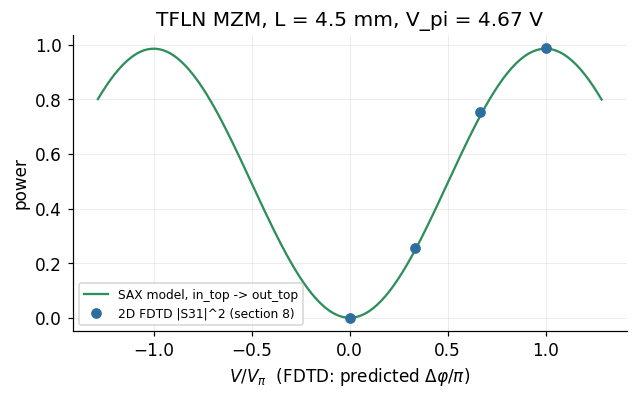

SAX model, V = 0, 1.30-1.40 um: bar + cross power in [0.977, 0.992]


In [30]:
import subprocess, sys
# Run the model in a fresh process to prove it never needs meep.
snippet = (
    "import sys, numpy as np; from pic_toolkit.models.tfln_mzm import tfln_mzm; "
    "assert 'meep' not in sys.modules; "
    "V = np.linspace(-6, 6, 241); "
    "T = [abs(tfln_mzm(1.35, v)[('in_top','out_top')])**2 for v in V]; "
    "print(','.join(f'{t:.6f}' for t in T))"
)
out = subprocess.run([sys.executable, "-c", snippet], capture_output=True, text=True, check=True).stdout.strip()
T_model = np.array([float(t) for t in out.split(",")])
V = np.linspace(-6, 6, 241)
fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.plot(V / VPI_DESIGN, T_model, color=style.COLOR_SEAGREEN, label="SAX model, in_top -> out_top")
ax.plot(dphi_pred / np.pi, T31, "o", color=style.COLOR_STEEL, label="2D FDTD |S31|^2 (section 8)")
ax.set_xlabel(r"$V/V_\pi$  (FDTD: predicted $\Delta\varphi/\pi$)"); ax.set_ylabel("power")
ax.set_title(f"TFLN MZM, L = {L_DESIGN_MM} mm, V_pi = {VPI_DESIGN:.2f} V"); ax.legend(fontsize=8); plt.show()

# Band-wide power check of the composed model at zero drive: bar + cross should stay
# just below 1 (two couplers' own ~1 % loss each) at every wavelength -- a dip would
# mean the complex S-parameter interpolation is cutting across a rotating phase.
snippet_band = (
    "import numpy as np; from pic_toolkit.models.tfln_mzm import tfln_mzm; "
    "wl = np.linspace(1.30, 1.40, 401); s = tfln_mzm(wl, 0.0); "
    "t = abs(s[('in_top','out_top')])**2 + abs(s[('in_top','out_bot')])**2; "
    "print(f'{t.min():.4f},{t.max():.4f}')"
)
tmin, tmax = map(float, subprocess.run([sys.executable, "-c", snippet_band], capture_output=True, text=True, check=True).stdout.split(","))
print(f"SAX model, V = 0, 1.30-1.40 um: bar + cross power in [{tmin:.3f}, {tmax:.3f}]")
assert tmin > 0.9 and tmax <= 1.01

Both arms share the same common phase, so output power depends only on the
push-pull phase difference and the two couplers: the model and the FDTD points
should fall on one curve. In practice the device is then biased to quadrature
(section 6.4) by a DC or thermal offset, which this equal-arm model leaves at zero.

## 12. Summary

- **Material.** x-cut TFLN uses the largest Pockels coefficient $r_{33}$ with a
  TE mode and lateral electrodes; the electro-optic response is linear and
  essentially instantaneous.
- **Optics.** The 1.0 $\mu$m rib on a 600 nm film (300 nm etch) is single-mode in
  TE; TE and TM are nearly degenerate, so the TE parity is forced in every solve.
- **Efficiency.** The overlap factor and $V_\pi L$ were computed by perturbation
  theory and cross-checked by a direct MPB re-solve; $V_\pi L$ lands in the
  range reported for real TFLN devices.
- **Interferometer.** A TFLN 50:50 coupler was designed (supermode seed, FDTD
  interpolation) and the full MZM was checked in 2D FDTD on a phase-equivalent
  shortened arm.
- **Bandwidth.** The electrode was analyzed as a quasi-TEM transmission line
  ($n_\mathrm{RF}$, $Z_0$, conductor loss all from the electrostatic solver);
  conductor loss dominates, and the electrode length sets the
  $V_\pi$-bandwidth trade-off, giving the design point saved above.

**Not modeled:** sidewall angle (vertical sidewalls assumed), optical absorption
by the metal and substrate leakage (proxies only), RF dielectric loss and
dispersion, DC bias drift, and the wavelength dependence of $r_{33}$ and
$\Gamma$ across the band.